# Predicting which coding bans a new model obeys: held-out-family demo on gemma-3-4b-it

**The question.** Tell an LLM *"Do not use Dijkstra's algorithm"*. Sometimes it obeys and writes a different correct
algorithm. Sometimes it ignores the ban and writes its default anyway. Can we predict which bans a model will obey
**without ever showing it a ban**?

**The method: a ban-free "push screen".** For each of 15 coding tasks, the model first writes programs for a neutral
**twin** prompt (token-matched to the ban prompt, with no ban). This gives its **default** algorithm D and the share p0
of programs that are not D. Then 8 fixed isotropic random directions (PCG64 seeds 9001-9008), at dose alpha in {1, 2},
are written into the hidden states of the task-description tokens. The edit acts on blocks 11-22 (the middle third of
34) during the prompt prefill only. It is *displacement-targeted*: the component along the direction is set to
alpha x n at every edited block, so the pushes do not compound. A direction **escapes** if it moves the model off D
without breaking correctness:

* at N = 10: off-default share - p0 >= 0.20 and pass rate >= 0.8 x the twin's;
* then, after a 20-sample top-up (N = 30): the same two criteria, plus an exact binomial test with p < 0.05.

**E_t** is the share of the 8 directions that escape. **MOVABLE** (E_t > 0) predicts that the model will **obey** a
ban of its default, meaning catalogue-only avoidance **A_t >= 0.5** over 100 ban programs.

**Pre-registration.** Every prediction and the analysis code were sha256 hash-chained *before any ban prompt was
built*. Only then were the 1,500 modal-ban programs sampled (5 ban templates x 20 sampling slots x 15 tasks) and
labelled.

**Stored findings, re-derived below:**

* **C3a** (does the screen predict compliance?) is **INCONCLUSIVE**: BA 0.739 [0.40, 0.95], Fisher p 0.235,
  Spearman rho 0.537 (one-sided permutation p 0.025).
* A rival does better: the off-default share under a plain *"write a novel algorithm"* instruction has rho 0.77.
* **C3b** (where do obeyed bans land?) is **INCONCLUSIVE**. The push-landing forecast scores -0.11 nats against
  -1.77 for "ask the model for the standard alternative", but there are only 2 disagreeing events (3 needed).
* **C1** (is temperature the creativity knob?) **no**. Plan noise (fresh random pushes) raises correct-only algorithm
  diversity (Hill-1) within 5 pass points (T2: 1.0 -> 1.62). Temperature 1.3 / 1.6 leaves it at 1.0.
* **Caveat (post hoc).** The frozen T2 labeller reads array-based Dijkstra as Bellman-Ford. A second judge's
  relabelling cuts T2 ban avoidance from 0.96 to 0.11. The verdict stays INCONCLUSIVE.

**What this notebook runs.** `method.py` drives 19 stages, each a script under `src/`. Generation is not re-run:
sampling the 10,730 programs took 1.28 GPU-hours on a 16 GB GPU. Labelling is not re-run either: it ran every program
against hidden tests, used an AST labeller and called OpenRouter judges. Their outputs enter as **per-task label
counts** in `mini_demo_data.json`: the artifact's `heldout_task_events` dataset, each task with its committed
screen cells, forecasts and arm compositions. Everything downstream is **recomputed on CPU with the original code**
and checked against the stored results:

| § | What | Original code |
|---|---|---|
| 1 | the pipeline driver | `method.py` |
| 4-5 | escape screen -> E_t, MOVABLE; ban-free rival predictors | `src/predictors.py` (commit #2) |
| 6 | the frozen, hash-committed analysis + its self-test | `predictions/analysis_c3.py` |
| 7-11 | ban outcome A_t, C3a + sensitivities, rivals, C3b, C1 diversity prices | `src/final_analysis.py` |
| 12 | C3a re-run under the post-hoc T2 relabelling | `src/posthoc_t2.py` |
| 13 | the push hook and push unit, run on a toy residual stack (GPU tests U1-U3) | `src/push.py`, `src/units.py`, `src/gpu_tests.py` |
| 14 | summary tables and figures | `src/figures.py` |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (method.py and every src/ stage log through loguru)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, pandas, torch -- pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')
    _pip('torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# method.py (pipeline driver)
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# src/predictors.py, predictions/analysis_c3.py (frozen analysis), src/final_analysis.py
import collections
import itertools
import json
import math
from typing import Any

import numpy as np
from scipy import stats

# src/push.py, src/units.py (displacement-targeted push and push unit)
import contextlib
from typing import Callable, Iterator

import torch

# notebook additions: tables and figures
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-4/experiment-23/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EXAMPLES = data["datasets"][0]["examples"]
print(data["metadata"]["source"])
print(f"{data['datasets'][0]['dataset']}: {len(EXAMPLES)} task events ->", [ex["metadata_task"] for ex in EXAMPLES])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
art_k6nzFCDLOjQP full_method_out.json, dataset heldout_task_events (all 15 task events), each enriched with its committed pre-ban record (predictions/commit_preban.json) and its C1 arm compositions (results/c1_prices.json)
heldout_task_events: 15 task events -> ['T1', 'T2', 'T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'R3', 'T13', 'R6', 'T14', 'T11', 'R2']


## Config

Every tunable parameter of the CPU stages is defined here. The analysis is per task (15 tasks), so the cost lies in
the Monte-Carlo loops: permutations, bootstraps, placebos and rarefaction draws. The values below are the
**frozen/original** ones that the pre-registered analysis used. At these values the recomputed statistics match the
stored results, and the whole notebook runs in about a minute on 2 CPUs, installs included.

**Quick smoke run.** The minimal configuration used in testing (about 30 s) is:

* `N_PERM = 200`, `N_BOOT = 20`, `N_PLACEBO = 20`, `C3B_N_PLACEBO = 10`;
* `SENS_N_PERM = 200`, `SENS_N_BOOT = 20`;
* `C1_N_TASKS = 2`, `C1_RAREFY_N_SUB = 10`, `C1_MC_N_SUB = 10`, `C1_HULL_GRID = 3`, `C1_BOOT_GRID = 3`, `C1_N_BOOT = 5`;
* `TOY_D_MODEL = 64`, `TOY_P = 8`, `TOY_B = 2`.

With fewer draws, the point estimates (BA, Fisher p, rho, log scores) stay the same. The permutation p-values, the
bootstrap intervals and the Monte-Carlo hull values get coarser. `C1_HULL_GRID` must stay >= 3, or the frozen
self-test's hull check cannot find an interior mixture.

In [5]:
# ---- frozen analysis (predictions/analysis_c3.py)
N_PERM = 100_000           # exact-permutation draws for Spearman's rho (frozen: 100_000)
N_BOOT = 2000             # task-bootstrap replicates for the BA / rho CIs and the rivals' delta-rho (frozen: 2_000)
N_PLACEBO = 2000          # task-label permutation placebo inside c3a() (frozen: 2000)
C3B_N_PLACEBO = 200       # shuffled-forecast placebo inside c3b() (frozen: 200)
# ---- C3a sensitivities and the post-hoc T2 re-run (src/final_analysis.py, src/posthoc_t2.py)
SENS_N_PERM = 20_000       # (original: 20000)
SENS_N_BOOT = 1000        # (original: 1000)
# ---- C1 diversity prices (src/final_analysis.py c1_prices() + the frozen hull functions)
C1_N_TASKS = 15           # tasks priced, in ALL_TASKS order (original: all 15)
C1_RAREFY_N_SUB = 1000    # random subsets for the rarefied Hill-1 at depth 25 (original: 1000)
C1_MC_N_SUB = 300         # multinomial draws per Monte-Carlo Hill-1 (frozen: 300)
C1_HULL_GRID = 21         # mixing weights per randomisation-hull segment (frozen: 21)
C1_BOOT_GRID = 11         # mixing weights inside the hull bootstrap (frozen: 11)
C1_N_BOOT = 100           # bootstrap replicates for the H5 interval (original: 100)
# ---- toy push check (src/push.py, src/units.py on a toy residual stack; the real run used gemma-3-4b-it)
TOY_D_MODEL = 2560       # toy residual width (gemma-3-4b-it: 2560)
TOY_P = 24               # toy prompt length; the "task spec" is positions [3, TOY_P - 3)
TOY_B = 8                # batch rows: half alpha 0, half pushed with alpha 1, 2, 1, 2, ... (GPU tests: 8)

## 1. The pipeline driver (`method.py`)

`method.py` runs the stages in order. Each stage is a separate script under `src/`, launched as a subprocess.
`--from <stage>` resumes and `--only <stage>` runs a single stage. A background label worker (`src/label_worker.py`)
labels every generated program from `pilot` until `bans`. `WAIT_BEFORE` makes a stage wait until the rows it needs
are labelled.

The code below is `method.py` verbatim, with two notebook changes. `ROOT` is the working directory, since a notebook
has no `__file__`. And `main()` is **not called**, because the stages need the full repository, the model weights on
a GPU and OpenRouter keys. The next cell lists where each stage's work appears in this notebook.

In [6]:
"""Predicting which bans a new model obeys -- held-out-family (gemma-3-4b-it) confirmation of Claim 3a.

Method (ours): a ban-free push screen. Eight fixed isotropic directions x alpha {1, 2} are written into the task-spec
states of the middle third of blocks (displacement-targeted, ban-free unit transferred from Qwen3-8B) on the
token-matched neutral twin prompt; a direction 'escapes' if it moves the model off its default algorithm without a
pass-rate cost (stage 1, N = 10) and survives a 20-sample confirmation with an exact binomial gate (N = 30).
E_t = share of escaping directions; MOVABLE = E_t > 0 predicts that the model will OBEY a ban of its default.
Baselines / rivals (same pipeline, same CRN slots): the un-pushed twin (zero dose), fresh-direction plan noise at
alpha 1 and 2, temperature 1.3, the novelty instruction (prompting ceiling), forced 'can' attempts, the twin's modal
share (how collapsed the default is), the opening-ladder margin; landing forecasts: push-landing, opening ladder,
association, AST proximity. All predictions are hash-committed (commit #2) before any ban prompt is built.

Pipeline (each stage is a module under src/; this driver runs them in order, resumable with --from):
  inputs     src/stage_inputs.py   stage inputs, sha256 checks, labeller re-check, dependency extraction
  screen     src/screen.py         iteration-3 screen file (shared protocol) + T5 reproduction
  qwen       src/qwen_ratio.py     Qwen3-8B ban-to-residual ratio r_Q (plain and outlier-excluded) + positive control
  gputests   src/gpu_tests.py      U1-U4, U6 on gemma
  probe      src/unit_probe.py     unit calibration probe (diagnostic; decided deviation D3)
  pilot      src/banfree.py pilot + commit1   pilot, default rule, cap rule, commit #1
  phaseA     src/banfree.py phaseA            twin N=50, escape stage 1, PN alpha 1/2, T 1.3 (CRN, B = 36)
  afterA     src/banfree.py all_after_A       confirmation top-up, association, opening ladder, novelty, 'can'
             (optional T 1.6 cell: src/banfree.py t16 --tasks <movable tasks>, run after the bans)
  commit2    src/commit2.py        grep audit + pre-ban predictions + frozen analysis hash (commit #2)
  bans       src/bans.py           1,500 modal-ban programs (+ extras) and the ban-derived unit
  audit      src/judge_audit.py    label audit, disagreement rates, novelty audit (OpenRouter, capped)
  analysis   src/final_analysis.py C3a, rivals, C3b, C1 prices, commit #3
  posthoc    src/posthoc_t2.py     POST HOC mechanism re-audit of T2 'bf_spfa' labels (array-Dijkstra), C3a re-run
  figures    src/figures.py
  tests      src/tests_cpu.py      CPU tests T1-T6
  rederive   audit/rederive.py     independent re-derivation of the headline numbers
  bookkeeping src/bookkeeping.py   timing summary and deviations log
  outputs    src/outputs.py        data/samples.jsonl, method_out.json (+ mini / preview)
The label worker (src/label_worker.py) runs in the background from 'pilot' to 'bans' and labels every raw row.
"""

# notebook: `from __future__ import annotations` and the imports are in the imports cell

ROOT = Path.cwd()  # notebook: no __file__ in a notebook (original: Path(__file__).resolve().parent)
PY = sys.executable
STAGES = [
    ("inputs", ["src/stage_inputs.py"]),
    ("screen", ["src/screen.py"]),
    ("qwen", ["src/qwen_ratio.py"]),
    ("gputests", ["src/gpu_tests.py"]),
    ("probe", ["src/unit_probe.py"]),
    ("pilot", ["src/banfree.py", "pilot"]),
    ("commit1", ["src/banfree.py", "commit1"]),
    ("phaseA", ["src/banfree.py", "phaseA"]),
    ("afterA", ["src/banfree.py", "all_after_A"]),
    ("commit2", ["src/commit2.py"]),
    ("bans", ["src/bans.py"]),
    ("audit", ["src/judge_audit.py"]),
    ("analysis", ["src/final_analysis.py"]),
    ("posthoc", ["src/posthoc_t2.py"]),
    ("figures", ["src/figures.py"]),
    ("tests", ["src/tests_cpu.py"]),
    ("rederive", ["audit/rederive.py"]),
    ("bookkeeping", ["src/bookkeeping.py"]),
    ("outputs", ["src/outputs.py"]),
]
WAIT_BEFORE = {"commit1": ["raw_pilot.jsonl"], "afterA": ["raw_phaseA.jsonl"],
               "commit2": ["raw_phaseA.jsonl", "raw_phaseB.jsonl", "raw_novelty.jsonl", "raw_can.jsonl"],
               "audit": ["raw_bans.jsonl"], "analysis": ["raw_bans.jsonl"]}

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(exist_ok=True)
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")


def run(cmd: list[str]) -> None:
    t0 = time.time()
    logger.info(f"running {' '.join(cmd)}")
    r = subprocess.run([PY] + cmd, cwd=ROOT)
    if r.returncode != 0:
        raise RuntimeError(f"stage failed ({r.returncode}): {' '.join(cmd)}")
    logger.info(f"done {' '.join(cmd)} in {time.time() - t0:.0f}s")


@logger.catch(reraise=True)
def main() -> None:
    names = [s for s, _ in STAGES]
    start = names[0]
    only = None
    if "--from" in sys.argv:
        start = sys.argv[sys.argv.index("--from") + 1]
    if "--only" in sys.argv:
        only = sys.argv[sys.argv.index("--only") + 1]
    labeller = None
    try:
        for name, cmd in STAGES[names.index(start):]:
            if only and name != only:
                continue
            if name == "pilot" and labeller is None:
                labeller = subprocess.Popen([PY, "src/label_worker.py"], cwd=ROOT,
                                            stdout=open(ROOT / "logs" / "label_worker.out", "a"),
                                            stderr=subprocess.STDOUT)
                logger.info(f"label worker started (pid {labeller.pid})")
            if name in WAIT_BEFORE and labeller is not None:
                run(["src/wait_labels.py"] + WAIT_BEFORE[name])
            run(cmd)
    finally:
        if labeller is not None:
            (ROOT / "data" / "STOP_LABELLER").touch()
            labeller.wait(timeout=600)
            (ROOT / "data" / "STOP_LABELLER").unlink(missing_ok=True)


# notebook: main() is not called -- every stage is a separate script under src/ that needs the full repository,
# the model weights on a GPU and OpenRouter keys; the CPU stages are re-run cell by cell below.
# if __name__ == "__main__":
#     main()

In [7]:
# notebook: where each stage's work appears in this notebook
WHERE = {
    "inputs": "not re-run: stages the upstream artifacts into inputs/ (sha256-checked)",
    "screen": "not re-run: the iteration-3 Qwen screen recomputed with this artifact's escape rule",
    "qwen": "GPU (Qwen3-8B): its ratio tables r_Q / r_Q,ox are loaded and drive the push unit in section 13",
    "gputests": "GPU: U1-U3 are mirrored on a toy residual stack in section 13",
    "probe": "GPU: push-unit calibration probe (deviation D3, see section 13)",
    "pilot": "GPU generation: its labels are summarised in the per-task counts",
    "commit1": "pilot rules + commit #1 (default algorithm D per task)",
    "phaseA": "GPU generation: twin, escape stage 1, plan noise, T 1.3 -> per-cell counts loaded",
    "afterA": "GPU generation: confirmation top-up, association, ladder, novelty, 'can' -> counts loaded",
    "commit2": "sections 4-5: escape screen -> E_t, MOVABLE; ban-free rivals (re-run on the committed counts)",
    "bans": "GPU generation: the 1,500 primary modal-ban programs -> label counts loaded",
    "audit": "OpenRouter judges: not re-run (the flagged tasks are loaded)",
    "analysis": "sections 7-11: A_t, C3a + sensitivities, rivals, C3b, C1 prices",
    "posthoc": "section 12: C3a re-run (the relabelling itself used an OpenRouter judge)",
    "figures": "section 14 (redrawn with matplotlib)",
    "tests": "section 6 runs the frozen analysis self-test (CPU test T5)",
    "rederive": "not re-run: reads the 18 MB row table data/samples.jsonl",
    "bookkeeping": "not re-run: timing summary and deviations log",
    "outputs": "not re-run: writes method_out.json (this demo's data source)",
}
for name, cmd in STAGES:
    wait = f" (waits for {', '.join(WAIT_BEFORE[name])})" if name in WAIT_BEFORE else ""
    print(f"{name:<12} {' '.join(cmd):<34} {WHERE[name]}{wait}")

inputs       src/stage_inputs.py                not re-run: stages the upstream artifacts into inputs/ (sha256-checked)
screen       src/screen.py                      not re-run: the iteration-3 Qwen screen recomputed with this artifact's escape rule
qwen         src/qwen_ratio.py                  GPU (Qwen3-8B): its ratio tables r_Q / r_Q,ox are loaded and drive the push unit in section 13
gputests     src/gpu_tests.py                   GPU: U1-U3 are mirrored on a toy residual stack in section 13
probe        src/unit_probe.py                  GPU: push-unit calibration probe (deviation D3, see section 13)
pilot        src/banfree.py pilot               GPU generation: its labels are summarised in the per-task counts
commit1      src/banfree.py commit1             pilot rules + commit #1 (default algorithm D per task) (waits for raw_pilot.jsonl)
phaseA       src/banfree.py phaseA              GPU generation: twin, escape stage 1, plan noise, T 1.3 -> per-cell counts loaded
afterA   

## 2. Shared constants (`src/cfg.py`)

These are the model, task and design constants of the experiment, copied verbatim. The paths, logging and file
helpers of `cfg.py` are left out because they belong to the repository layout.

* **15 tasks.** T1 is a grid path and T2 a weighted shortest path; the 12 bench tasks are T03-T14 and R1/R3/R6, plus R2.
* **Templates.** There are 5 ban templates W1-W5, each paired with a neutral twin built from the same template.
* **Escape rule.** The thresholds are `ESCAPE_EXCESS = 0.20`, `ESCAPE_PASS_FRAC = 0.80`, `BINOM_ALPHA = 0.05` and
  `P0_FLOOR = 0.01`.
* **Compliance.** The threshold is `COMPLY_THRESH = 0.5`.

In [8]:
# src/cfg.py -- model, task and design constants (verbatim; paths, logging and file utilities omitted)
# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "google/gemma-3-4b-it"
MODEL_REVISION = "093f9f388b31de276ce2de164bdc2081324b9767"
FALLBACK_MODEL_ID = "Qwen/Qwen2.5-Coder-7B-Instruct"
QWEN_ID = "Qwen/Qwen3-8B"
QWEN_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
QWEN_LAYERS = 36
QWEN_BAND = list(range(12, 24))   # blocks whose ban displacement norms exp13/exp17 recorded
N_LAYERS = 34
D_MODEL = 2560
BAND = list(range(11, 23))        # middle third of 34 blocks
CAPTURE_BLOCKS = list(range(11, 34))  # realised displacement logged from BAND start to the last block
BOS_ID = 2
EOS_ID = 1
EOT_ID = 106                      # <end_of_turn>
STOP_IDS = (EOS_ID, EOT_ID)
PAD_ID = 0
CHAT_HEAD = "<bos><start_of_turn>user\n"
CHAT_TAIL = "<end_of_turn>\n<start_of_turn>model\n"
MAX_NEW_BENCH = 1024
MAX_NEW_PATH = 1536
MAX_NEW_ASSOC = 160
CAP_FLOOR = 640
STOP_CHECK_EVERY = 16
DECODING = "T1.0_topp1.0_topk-off_inverse-CDF-CRN"
PRECISION = "bf16 (sdpa attention); logits fp32, CDF float64"

# ------------------------------------------------------------------------------------------------ tasks
PATH_TASKS = ("T1", "T2")
BENCH12 = ("T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11")
BENCH_TASKS = BENCH12 + ("R2",)
ALL_TASKS = PATH_TASKS + BENCH_TASKS      # 15 tasks
QWEN_RATIO_TASKS = PATH_TASKS + BENCH12   # the 14 tasks with Qwen ban-displacement norms (no R2)
EXP8_TASK = {"T1": "t1", "T2": "t2"}
QWEN_DEFAULT = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort", "T04": "naive", "T06": "hash_set",
                "T05": "hash_map", "T10": "union_find", "R1": "greedy_end", "T08": "iteration", "R3": "kahn",
                "T13": "sort_sweep", "R6": "binary_search", "T14": "sort_by_count", "T11": "quadratic_dp",
                "R2": "dfs_parent"}
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral twin) -- protocol W1-W5, verbatim
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
PAD_FILLER = " ."
MAX_PAD = 24
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."

# ------------------------------------------------------------------------------------------------ design
ESCAPE_SEEDS = tuple(range(9001, 9009))   # 8 fixed isotropic directions
ALPHAS = (1.0, 2.0)
T_HOT = 1.3
N_TWIN_PER_T = 10                          # twin slots 0-9 per template (N = 50 per task)
N_STAGE1_PER_T = 2                         # escape stage 1: slots 0-1 per template (N = 10 per direction-alpha)
STAGE2_SLOTS = (2, 3, 4, 5)                # confirmation top-up (N = 20 more)
N_PN_PER_T = 10
N_T13_PER_T = 10
N_BAN_PER_T = 20                           # ban slots 0-19 per template (N = 100 per task, primary)
ESCAPE_EXCESS = 0.20
ESCAPE_PASS_FRAC = 0.80
BINOM_ALPHA = 0.05
P0_FLOOR = 0.01
COMPLY_THRESH = 0.5
SMOOTH = {"f": 0.93, "uniform_S": 0.05, "other": 0.02}
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
OPENROUTER_CAP_USD = 1.00

## 3. The per-task records

The repository's stages read the committed pre-ban record `predictions/commit_preban.json`, the ban outcome table
`results/bans.json`, the C1 arm table `results/c1_prices.json` and the label audit. Here the same per-task records
come from `mini_demo_data.json`. The table shows each task's default algorithm D (the twin's modal correct program),
the other algorithms in its catalogue (the **survivors** a ban could move it to), and the ban the model later
received.

In [9]:
# notebook glue: the per-task records the stages below read from predictions/commit_preban.json,
# results/bans.json, results/c1_prices.json and results/label_audit.json in the repository
EV = {ex["metadata_task"]: ex for ex in EXAMPLES}
pre = {"tasks": {t: {**json.loads(EV[t]["metadata_preban"]), "rivals": json.loads(EV[t]["metadata_rivals"])}
                 for t in ALL_TASKS},
       "rival_signs": data["metadata"]["rival_signs"]}
bans_stored = {t: json.loads(EV[t]["metadata_outcome"]) for t in ALL_TASKS}     # results/bans.json
c1_arms = {t: json.loads(EV[t]["metadata_c1_arms"]) for t in ALL_TASKS}          # results/c1_prices.json (arms)
c1_hull_stored = {t: json.loads(EV[t]["metadata_c1_hull"]) for t in ALL_TASKS}   # results/c1_prices.json (hull)
REF = data["metadata"]["reference_results"]                                       # stored c3a / rivals / c3b


def modes(t: str) -> list[str]:
    """The task's algorithm catalogue (src/prompts_gemma.py modes()): the default D plus its survivors."""
    return [pre["tasks"][t]["D"]] + pre["tasks"][t]["survivors"]


display(pd.DataFrame([{"task": t, "default D (twin's modal program)": pre["tasks"][t]["D_display"],
                       "survivors (rest of the catalogue)": ", ".join(pre["tasks"][t]["survivors"]),
                       "twin N": pre["tasks"][t]["n_twin"], "twin pass": pre["tasks"][t]["twin_pass"],
                       "twin share of D": bans_stored[t]["twin_default_share"],
                       "ban (5 templates x 20 slots)": EV[t]["input"].split(": ", 1)[1].split(";")[0]}
                      for t in ALL_TASKS]).set_index("task"))

,default D (twin's modal program),survivors (rest of the catalogue),twin N,twin pass,twin share of D,ban (5 templates x 20 slots)
task,,,,,,
T1,depth-first search (DFS),"bfs, bibfs, iddfs, astar_gbfs, dijkstra",50,0.82,0.50,modal ban of 'depth-first search (DFS)' (dfs)
T2,Dijkstra's algorithm,"bf_spfa, bidijkstra, floyd, dial",50,1.00,1.00,modal ban of 'Dijkstra's algorithm' (dijkstra)
T03,a full sort,"size_k_heap, heapify_pop, quickselect, median_...",50,1.00,1.00,modal ban of 'a full sort' (full_sort)
T04,the naive sliding-window comparison,"kmp, rabin_karp, z_algorithm, bmh, builtin",50,1.00,0.92,modal ban of 'the naive sliding-window compari...
T06,a hash set of seen values,"sort_adjacent, floyd, value_binary_search, ind...",50,1.00,1.00,modal ban of 'a hash set of seen values' (hash...
T05,a hash map of seen values,"sort_two_pointers, brute_force, sort_binary_se...",50,1.00,1.00,modal ban of 'a hash map of seen values' (hash...
T10,depth-first search (DFS),"bfs, union_find, label_propagation",50,1.00,1.00,modal ban of 'depth-first search (DFS)' (dfs)
R1,the greedy earliest-finish rule,"dp_bisect, memo_recursion, dag_longest_path",50,1.00,1.00,modal ban of 'the greedy earliest-finish rule'...
T08,bottom-up iteration,"memo_recursion, matrix_power, fast_doubling",50,1.00,1.00,modal ban of 'bottom-up iteration' (iteration)


## 4. The escape screen: E_t and MOVABLE (`src/predictors.py`, run in commit #2)

This is the method itself, applied **before any ban exists**. The cells come from the twin prompt with each of the
16 direction-alpha pushes:

* **Stage 1 (N = 10 per cell).** A cell passes if `off_share - p0 >= 0.20` and `pass >= 0.8 x twin pass`.
* **Confirmation (N = 30).** A cell that passed stage 1 gets 20 more samples and must pass both criteria again. It
  also needs an exact binomial `P(X >= k | 30, max(p0, 0.01)) < 0.05`.
* **E_t** = max over alpha of (#confirmed directions / 8). **MOVABLE** = E_t > 0.

*Off-default* means a label that is neither D, `invalid` nor `disputed`. In the repository, `stage1()` and
`confirm()` count off-default and passing programs over the label rows of each cell. Here they read the same counts
from the committed cells: n, off-default share and pass rate at stage 1, and n, k_off and pass rate at N = 30. The
decision rule is the original code, so it must reproduce the committed E_t, the confirmed directions and MOVABLE
exactly.

In [10]:
NOT_OFF = ("invalid", "disputed")


def stage1(t: str) -> dict[str, Any]:
    # notebook: the committed stage-1 cell counts (n, off-default share, pass rate) replace off_share(rr, D) and
    # pass_rate(rr) over the cell's label rows; the twin's p0 and pass rate (N = 50) likewise
    rec = pre["tasks"][t]
    D = rec["D"]
    p0, pt = rec["p0"], rec["twin_pass"]
    cells, passing = {}, []
    for s in ESCAPE_SEEDS:
        for a in ALPHAS:
            c = rec["stage1_cells"][f"{s}_a{int(a)}"]
            sh, pr = c["off_share"], c["pass"]
            ok = bool(c["n"]) and (sh - p0 >= ESCAPE_EXCESS) and (pr >= ESCAPE_PASS_FRAC * pt)
            cells[f"{s}_a{int(a)}"] = {"n": c["n"], "off_share": sh, "excess": sh - p0, "pass": pr, "stage1_pass": ok}
            if ok:
                passing.append((s, a))
    return {"D": D, "p0": p0, "twin_pass": pt, "n_twin": rec["n_twin"], "cells": cells, "passing": passing}


def confirm(t: str) -> dict[str, Any]:
    st = stage1(t)
    D, p0, pt = st["D"], st["p0"], st["twin_pass"]
    conf = []
    cells = {}
    for (s, a) in st["passing"]:
        c = pre["tasks"][t]["confirm_cells"][f"{s}_a{int(a)}"]  # notebook: N = 30 counts (stage 1 + top-up)
        n = c["n"]
        k = c["k_off"]
        sh, pr = (k / n if n else float("nan")), c["pass"]
        pb = float(stats.binom.sf(k - 1, n, max(p0, P0_FLOOR))) if n else 1.0
        ok = n >= 30 and (sh - p0 >= ESCAPE_EXCESS) and (pr >= ESCAPE_PASS_FRAC * pt) and pb < BINOM_ALPHA
        cells[f"{s}_a{int(a)}"] = {"n": n, "k_off": k, "off_share": sh, "excess": sh - p0, "pass": pr,
                                   "binom_p": pb, "confirmed": ok}
        if ok:
            conf.append((s, a))
    E = {}
    for a in ALPHAS:
        E[f"a{int(a)}"] = sum(1 for (s, aa) in conf if aa == a) / len(ESCAPE_SEEDS)
    Et = max(E.values()) if E else 0.0
    kmax = int(round(Et * len(ESCAPE_SEEDS)))
    lo, hi = stats.binomtest(kmax, len(ESCAPE_SEEDS)).proportion_ci(method="exact") if True else (0, 0)
    return {**st, "confirm_cells": cells, "confirmed": conf, "E_alpha": E, "E_t": Et, "E_t_ci95": [lo, hi],
            "movable": Et > 0, "n_directions_run": len(ESCAPE_SEEDS)}


screen = {t: confirm(t) for t in ALL_TASKS}
screen_tab = pd.DataFrame([{
    "task": t, "D": screen[t]["D"], "p0": round(screen[t]["p0"], 2), "twin pass": screen[t]["twin_pass"],
    "stage-1 passing cells": len(screen[t]["passing"]),
    "confirmed (seed, alpha)": [(s, int(a)) for s, a in screen[t]["confirmed"]],
    "E_t": screen[t]["E_t"], "MOVABLE": screen[t]["movable"],
    "E_t 95% CI (exact)": [round(x, 2) for x in screen[t]["E_t_ci95"]],
    "= committed": (screen[t]["E_t"] == pre["tasks"][t]["E_t"] and screen[t]["movable"] == pre["tasks"][t]["movable"]
                    and [[s, a] for s, a in screen[t]["confirmed"]] == pre["tasks"][t]["confirmed"])}
    for t in ALL_TASKS]).set_index("task")
display(screen_tab)
print("MOVABLE (predicted to obey a ban of D):", [t for t in ALL_TASKS if screen[t]["movable"]])
print("all recomputed screen decisions equal the committed ones:", bool(screen_tab["= committed"].all()))

,D,p0,twin pass,stage-1 passing cells,"confirmed (seed, alpha)",E_t,MOVABLE,E_t 95% CI (exact),= committed
task,,,,,,,,,
T1,dfs,0.50,0.82,2,"[(9003, 1), (9003, 2)]",0.125,True,"[0.0, 0.53]",True
T2,dijkstra,0.00,1.00,4,"[(9004, 1), (9004, 2), (9007, 1), (9007, 2)]",0.250,True,"[0.03, 0.65]",True
T03,full_sort,0.00,1.00,0,[],0.000,False,"[0.0, 0.37]",True
T04,naive,0.08,1.00,4,"[(9001, 1), (9001, 2), (9003, 1), (9003, 2)]",0.250,True,"[0.03, 0.65]",True
T06,hash_set,0.00,1.00,0,[],0.000,False,"[0.0, 0.37]",True
T05,hash_map,0.00,1.00,2,"[(9003, 2), (9004, 2)]",0.250,True,"[0.03, 0.65]",True
T10,dfs,0.00,1.00,1,"[(9002, 2)]",0.125,True,"[0.0, 0.53]",True
R1,greedy_end,0.00,1.00,0,[],0.000,False,"[0.0, 0.37]",True
T08,iteration,0.00,1.00,0,[],0.000,False,"[0.0, 0.37]",True


MOVABLE (predicted to obey a ban of D): ['T1', 'T2', 'T04', 'T05', 'T10', 'T11']
all recomputed screen decisions equal the committed ones: True


## 5. Ban-free rival predictors (`src/predictors.py` `rivals()`, commit #2)

Competing ban-free signals were committed next to E_t. All are measured in the same engine on the same twin prompt,
with the same common random numbers:

| Rival | What it measures |
|---|---|
| `twin_modal_share`, `twin_modal_share_correct` | how collapsed the default is |
| `can_max` | the best pass-rate when the model is *asked* to use a specific survivor |
| `t13_off` | off-default share at temperature 1.3 |
| `pn_a1_off`, `pn_a2_off` | off-default share under fresh-direction plan noise at alpha 1 and 2 |
| `novelty_off` | off-default share under the instruction *"Write a novel algorithm for this task, one you have not seen before"* (the prompting ceiling) |
| `opening_margin` | the teacher-forced opening-ladder margin |

The function below is `rivals()` with the label rows replaced by each arm's label counts. It is renamed
`banfree_rivals()` because the frozen analysis also defines a `rivals()`. `can_max` and `opening_margin` need
generation and teacher forcing on the GPU, so they are taken as committed.

In [11]:
def off_share_counts(comp: dict[str, int], n: int, D: str) -> float:
    """off_share() over an arm's label counts instead of its label rows."""
    return sum(v for k, v in comp.items() if k not in (D,) + NOT_OFF) / n if n else float("nan")


def banfree_rivals(t: str, D: str, ladder: dict[str, Any] | None) -> dict[str, Any]:  # src/predictors.py rivals()
    arms = c1_arms[t]  # notebook: per-arm label counts (stage A twin / t13 / pn_a1 / pn_a2, stage C novelty)
    tw = arms["twin"]
    cnt = collections.Counter(tw["attempt_comp"])
    cc = collections.Counter(tw["correct_comp"])
    n_tw, n_corr = tw["n"], sum(cc.values())
    out = {"twin_modal_share": (cnt.most_common(1)[0][1] / n_tw) if n_tw else None,
           "twin_modal_share_correct": (cc.most_common(1)[0][1] / n_corr) if n_corr else None,
           "twin_default_share": (cnt.get(D, 0) / n_tw) if n_tw else None}
    out.update({"can": pre["tasks"][t]["rivals"]["can"]})  # notebook: the forced 'can' arm (stage D), as committed
    out["can_max"] = out["can"]["can_max"]
    for key, arm in (("t13_off", "t13"), ("pn_a1_off", "pn_a1"), ("pn_a2_off", "pn_a2"), ("novelty_off", "novelty")):
        rr = arms.get(arm)
        out[key] = off_share_counts(rr["attempt_comp"], rr["n"], D) if rr else None
        out[key.replace("_off", "_pass")] = rr["pass"] if rr else None
        out[key.replace("_off", "_n")] = rr["n"] if rr else 0
    out["opening_margin"] = (ladder or {}).get("margin")
    return out


RIVAL_KEYS = ["twin_modal_share", "twin_modal_share_correct", "can_max", "t13_off", "novelty_off", "pn_a1_off",
              "pn_a2_off", "opening_margin"]
rv_banfree = {t: banfree_rivals(t, pre["tasks"][t]["D"], {"margin": pre["tasks"][t]["opening_margin"]})
              for t in ALL_TASKS}
same = all(rv_banfree[t][k] == pre["tasks"][t]["rivals"][k] for t in ALL_TASKS for k in RIVAL_KEYS)
display(pd.DataFrame({t: {k: rv_banfree[t][k] for k in RIVAL_KEYS} for t in ALL_TASKS}).T.round(3))
print("recomputed rivals equal the committed ones:", same)

,twin_modal_share,twin_modal_share_correct,can_max,t13_off,novelty_off,pn_a1_off,pn_a2_off,opening_margin
T1,0.50,0.585,0.8,0.54,0.66,0.58,0.66,0.000
T2,1.00,1.000,1.0,0.00,0.64,0.10,0.30,-2.899
T03,1.00,1.000,1.0,0.02,0.90,0.08,0.12,18.677
T04,0.92,0.920,1.0,0.08,0.66,0.20,0.14,-26.476
T06,1.00,1.000,1.0,0.00,0.88,0.00,0.02,16.340
T05,1.00,1.000,1.0,0.00,0.02,0.00,0.02,7.532
T10,1.00,1.000,1.0,0.00,0.02,0.06,0.18,-20.220
R1,1.00,1.000,0.0,0.00,0.00,0.00,0.00,0.000
T08,1.00,1.000,1.0,0.00,0.00,0.00,0.00,16.626
R3,1.00,1.000,0.0,0.00,0.00,0.00,0.00,NaN


recomputed rivals equal the committed ones: True


## 6. The frozen analysis (`predictions/analysis_c3.py`)

This file was copied into `predictions/` and **sha256 hash-committed in commit #2, before any ban prompt existed**.
The three cells below are the file verbatim, apart from the imports (in the imports cell) and the Monte-Carlo sizes,
which now come from the config cell. With the frozen config values the behaviour is identical.

* **C3a.** Balanced accuracy of MOVABLE against C_t = 1[A_t >= 0.5], a Fisher exact test on the 2x2 table, and an
  exact-permutation Spearman(E_t, A_t). The verdict is CONFIRMED iff BA >= 0.8 and Fisher p < 0.05 and rho >= 0.5,
  DISCONFIRMED iff BA <= 0.6, and INCONCLUSIVE otherwise. Task-bootstrap CIs, a task-permutation placebo and
  leave-one-task-out values are reported next to it.
* **Rivals.** Each rival's sign-oriented Spearman with A_t, the paired-bootstrap delta-rho, and the partial Spearman of
  E_t given the rival.
* **C3b.** Smoothed log scores of each landing forecast on the realised ban landings. The pre-registered contest is
  that a ban-free forecast beats "association" by >= 0.10 nats on >= 3 disagreeing events.
* **C1.** Correct-only rarefied Hill-1, the "effective number of algorithms" among correct programs, at depth 25. H5
  is the best Hill-1 reachable within 5 pass points on the randomisation hull of a knob (mixtures twin -> setting).

In [12]:
# predictions/analysis_c3.py (FROZEN) -- part 1: basic statistics and C3a
"""FROZEN ANALYSIS (hash-committed in commit #2, before any ban prompt reaches the model).

C3a (primary): per task, A_t = catalogue-only avoidance = #(ban attempts with label in catalogue minus {D}) / N_ban,
C_t = 1[A_t >= 0.5]. Prediction: MOVABLE (E_t > 0) -> predicted to obey (C_t = 1).
  BA = (TPR + TNR) / 2 with positive class C_t = 1; two-sided Fisher exact (one-sided 'greater' too); exact permutation
  Spearman(E_t, A_t) (1e5 permutations, average ranks) with Kendall tau-b beside it.
  Verdict: CONFIRMED iff BA >= 0.8 AND Fisher p < 0.05 AND rho >= 0.5; DISCONFIRMED iff BA <= 0.6; else INCONCLUSIVE.
  Edge cases: all tasks in one compliance class -> BA untestable, Spearman alone; a single predicted class -> BA 0.5
  ('no discrimination'), disconfirming only if both outcome classes exist; ties in E_t -> average ranks.
  Task bootstrap (2,000) CIs for BA and rho; task-label permutation placebo; leave-one-task-out BA and rho;
  conservative primary-family bound min(1, 3p).
Rivals: sign-oriented Spearman with A_t, paired task-bootstrap delta-rho, partial Spearman of E_t given each rival,
  BA of a median-threshold rule (reported, not optimised).
C3b: p' = 0.93 p + 0.05 uniform(survivors) + 0.02 'other'; realised = ban attempts with label not in {D, invalid,
  disputed}; mean log score per event; top-1 hit vs the modal realised catalogue landing (fractional tie credit
  separately; defined-only hit rates); contest: a ban-free forecast (push-landing or ladder) beats association by
  >= 0.10 nats on >= 3 disagreeing events; paired Wilcoxon (Holm over the two comparisons) if >= 10 disagreeing.
C1 (descriptive): correct-only rarefied Hill-1 at depth 25; pass cost = 100 x (pass_twin - pass_arm) floored at 0;
  H5 / P15 / P20 = best correct-only Hill-1 within 5 / 15 / 20 pass points on the randomisation hull of each knob
  class (mixtures twin->setting and between adjacent settings; Monte-Carlo rarefaction at depth 25).
"""

# notebook: imports are in the imports cell

SMOOTH = {"f": 0.93, "uniform_S": 0.05, "other": 0.02}
NOT_OFF = ("invalid", "disputed")
# notebook: N_PERM and N_BOOT are set in the config cell (frozen values: 100_000 and 2_000)


# ------------------------------------------------------------------------------------------------ basic statistics
def rankdata(x: np.ndarray) -> np.ndarray:
    return stats.rankdata(x, method="average")


def spearman(x: np.ndarray, y: np.ndarray) -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3 or np.std(x) == 0 or np.std(y) == 0:
        return float("nan")
    rx, ry = rankdata(x), rankdata(y)
    return float(np.corrcoef(rx, ry)[0, 1])


def perm_spearman(x: np.ndarray, y: np.ndarray, n_perm: int = N_PERM, seed: int = 0) -> dict[str, Any]:
    x, y = np.asarray(x, float), np.asarray(y, float)
    rho = spearman(x, y)
    if not np.isfinite(rho):
        return {"rho": None, "p_one_sided": None, "p_two_sided": None, "n": len(x), "note": "constant input"}
    rx, ry = rankdata(x), rankdata(y)
    rx = (rx - rx.mean()) / rx.std()
    ry = (ry - ry.mean()) / ry.std()
    rng = np.random.default_rng(seed)
    perm = np.argsort(rng.random((n_perm, len(x))), axis=1)
    rp = (rx[None, :] * ry[perm]).mean(1)
    return {"rho": rho, "p_one_sided": float((np.sum(rp >= rho - 1e-12) + 1) / (n_perm + 1)),
            "p_two_sided": float((np.sum(np.abs(rp) >= abs(rho) - 1e-12) + 1) / (n_perm + 1)), "n": len(x)}


def kendall(x, y) -> float | None:
    if len(set(x)) < 2 or len(set(y)) < 2:
        return None
    return float(stats.kendalltau(x, y, variant="b").statistic)


def balanced_accuracy(pred: list[int], obs: list[int]) -> dict[str, Any]:
    pred, obs = np.asarray(pred, int), np.asarray(obs, int)
    pos, neg = obs == 1, obs == 0
    out = {"n_pos": int(pos.sum()), "n_neg": int(neg.sum()), "n_pred_pos": int(pred.sum()),
           "n_pred_neg": int((1 - pred).sum())}
    if pos.sum() == 0 or neg.sum() == 0:
        out.update(BA=None, TPR=None, TNR=None, testable=False, note="all tasks in one compliance class")
        return out
    tpr = float((pred[pos] == 1).mean())
    tnr = float((pred[neg] == 0).mean())
    out.update(BA=(tpr + tnr) / 2, TPR=tpr, TNR=tnr, testable=True,
               single_predicted_class=bool(pred.min() == pred.max()))
    return out


def fisher(pred: list[int], obs: list[int]) -> dict[str, Any]:
    pred, obs = np.asarray(pred, int), np.asarray(obs, int)
    tab = [[int(((pred == 1) & (obs == 1)).sum()), int(((pred == 1) & (obs == 0)).sum())],
           [int(((pred == 0) & (obs == 1)).sum()), int(((pred == 0) & (obs == 0)).sum())]]
    if (pred.min() == pred.max()) or (obs.min() == obs.max()):
        return {"table": tab, "p_two_sided": 1.0, "p_greater": 1.0, "note": "degenerate margin"}
    return {"table": tab, "p_two_sided": float(stats.fisher_exact(tab, alternative="two-sided").pvalue),
            "p_greater": float(stats.fisher_exact(tab, alternative="greater").pvalue)}


# ------------------------------------------------------------------------------------------------ C3a
def c3a(tasks: list[str], E: dict[str, float], A: dict[str, float], movable: dict[str, bool] | None = None,
        thresh: float = 0.5, seed: int = 0, n_perm: int = N_PERM, n_boot: int = N_BOOT) -> dict[str, Any]:
    tasks = [t for t in tasks if t in E and t in A and E[t] is not None and A[t] is not None]
    e = np.array([E[t] for t in tasks], float)
    a = np.array([A[t] for t in tasks], float)
    mv = np.array([int((movable or {}).get(t, E[t] > 0)) for t in tasks])
    C = (a >= thresh).astype(int)
    ba = balanced_accuracy(mv, C)
    fi = fisher(mv, C)
    sp = perm_spearman(e, a, n_perm=n_perm, seed=seed)
    kt = kendall(list(e), list(a))
    rho = sp["rho"]
    if not ba["testable"]:
        verdict = "UNTESTABLE_BA (Spearman alone)"
        if rho is not None:
            verdict += f": rho={rho:.3f}"
    else:
        b = ba["BA"]
        if b >= 0.8 and fi["p_two_sided"] < 0.05 and rho is not None and rho >= 0.5:
            verdict = "CONFIRMED"
        elif b <= 0.6:
            verdict = "DISCONFIRMED"
        else:
            verdict = "INCONCLUSIVE"
    rng = np.random.default_rng(seed + 1)
    bb, br = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(tasks), len(tasks))
        r = balanced_accuracy(mv[idx], C[idx])
        if r["BA"] is not None:
            bb.append(r["BA"])
        rr = spearman(e[idx], a[idx])
        if np.isfinite(rr):
            br.append(rr)
    boot = {"BA_ci95": [float(np.quantile(bb, 0.025)), float(np.quantile(bb, 0.975))] if bb else None,
            "rho_ci95": [float(np.quantile(br, 0.025)), float(np.quantile(br, 0.975))] if br else None,
            "n_valid_BA": len(bb), "n_valid_rho": len(br)}
    # task-label permutation placebo: shuffle the outcome across tasks
    rng = np.random.default_rng(seed + 2)
    pl_ba, pl_rho = [], []
    for _ in range(N_PLACEBO):  # notebook: config (frozen: 2000)
        p = rng.permutation(len(tasks))
        r = balanced_accuracy(mv, C[p])
        if r["BA"] is not None:
            pl_ba.append(r["BA"])
        rr = spearman(e, a[p])
        if np.isfinite(rr):
            pl_rho.append(rr)
    placebo = {"BA_mean": float(np.mean(pl_ba)) if pl_ba else None,
               "BA_p_ge_observed": (float(np.mean(np.array(pl_ba) >= ba["BA"] - 1e-12)) if (pl_ba and ba["BA"] is not None)
                                    else None),
               "rho_mean": float(np.mean(pl_rho)) if pl_rho else None}
    loo = {}
    for i, t in enumerate(tasks):
        m = np.arange(len(tasks)) != i
        r = balanced_accuracy(mv[m], C[m])
        loo[t] = {"BA": r["BA"], "rho": spearman(e[m], a[m])}
    p_raw = fi["p_two_sided"]
    return {"tasks": tasks, "E_t": dict(zip(tasks, e.tolist())), "A_t": dict(zip(tasks, a.tolist())),
            "movable": dict(zip(tasks, mv.tolist())), "C_t": dict(zip(tasks, C.tolist())), "balanced_accuracy": ba,
            "fisher": fi, "spearman": sp, "kendall_tau_b": kt, "verdict": verdict, "fisher_p_raw": p_raw,
            "fisher_p_bonferroni3": min(1.0, 3 * p_raw), "bootstrap": boot, "placebo_task_permutation": placebo,
            "leave_one_task_out": loo}

In [13]:
# predictions/analysis_c3.py (FROZEN) -- part 2: rivals and C3b
# ------------------------------------------------------------------------------------------------ rivals
def partial_spearman(x, y, z) -> float | None:
    x, y, z = (rankdata(np.asarray(v, float)) for v in (x, y, z))
    if np.std(z) == 0:
        return spearman(x, y)
    rxy, rxz, ryz = (np.corrcoef(p, q)[0, 1] for p, q in ((x, y), (x, z), (y, z)))
    den = math.sqrt(max(1e-12, (1 - rxz ** 2) * (1 - ryz ** 2)))
    v = (rxy - rxz * ryz) / den
    return float(v) if np.isfinite(v) else None


def rivals(tasks: list[str], E: dict[str, float], A: dict[str, float], R: dict[str, dict[str, float | None]],
           sign: dict[str, int], seed: int = 0, n_boot: int = N_BOOT) -> dict[str, Any]:
    out = {}
    for name, vals in R.items():
        tt = [t for t in tasks if vals.get(t) is not None and E.get(t) is not None and A.get(t) is not None]
        if len(tt) < 4:
            out[name] = {"n": len(tt), "note": "too few defined tasks"}
            continue
        e = np.array([E[t] for t in tt])
        a = np.array([A[t] for t in tt])
        r = sign.get(name, 1) * np.array([vals[t] for t in tt], float)
        rho_r, rho_e = spearman(r, a), spearman(e, a)
        rng = np.random.default_rng(seed + hash(name) % 1000)
        d = []
        for _ in range(n_boot):
            idx = rng.integers(0, len(tt), len(tt))
            x1, x2 = spearman(e[idx], a[idx]), spearman(r[idx], a[idx])
            if np.isfinite(x1) and np.isfinite(x2):
                d.append(x1 - x2)
        med = np.median(r)
        pred = (r > med).astype(int)
        C = (a >= 0.5).astype(int)
        out[name] = {"n": len(tt), "rho_rival_sign_oriented": rho_r, "rho_E_t_same_tasks": rho_e,
                     "delta_rho": (rho_e - rho_r) if (np.isfinite(rho_e) and np.isfinite(rho_r)) else None,
                     "delta_rho_ci95": [float(np.quantile(d, 0.025)), float(np.quantile(d, 0.975))] if d else None,
                     "partial_spearman_E_given_rival": partial_spearman(e, a, r),
                     "median_threshold_BA": balanced_accuracy(pred, C)["BA"], "sign": sign.get(name, 1)}
    return out


# ------------------------------------------------------------------------------------------------ C3b
def smooth(p: dict[str, float], S: list[str]) -> dict[str, float]:
    out = {m: SMOOTH["f"] * p.get(m, 0.0) + SMOOTH["uniform_S"] / len(S) for m in S}
    out["other"] = SMOOTH["other"]
    return out


def log_score(p: dict[str, float], labels: list[str], S: list[str]) -> float | None:
    ps = smooth(p, S)
    xs = [math.log(ps.get(l if l in S else "other", ps["other"])) for l in labels]
    return float(np.mean(xs)) if xs else None


def top1_hit(top: str | None, labels: list[str], S: list[str]) -> dict[str, Any]:
    c = collections.Counter(l for l in labels if l in S)
    if not c or top is None:
        return {"hit": None, "frac": None, "modal": sorted(c)[:1] if c else None}
    mx = max(c.values())
    modal = sorted(m for m, v in c.items() if v == mx)
    return {"hit": int(top in modal and len(modal) == 1) if len(modal) == 1 else int(top in modal),
            "frac": (1 / len(modal)) if top in modal else 0.0, "modal": modal}


def c3b(events: dict[str, dict[str, Any]], seed: int = 0) -> dict[str, Any]:
    """events[t] = {'S': survivors, 'labels': realised ban labels (not D/invalid/disputed), 'forecasts':
    {name: {'distribution', 'top1', 'defined'}}}."""
    names = ["push_landing", "opening_ladder", "association", "proximity"]
    per = {}
    for t, ev in events.items():
        S, labs = ev["S"], ev["labels"]
        row = {"n_realised": len(labs), "realised": dict(collections.Counter(labs))}
        for nm in names:
            f = ev["forecasts"].get(nm) or {}
            dist = f.get("distribution") if f.get("defined") else {m: 1 / len(S) for m in S}
            row[nm] = {"log_score": log_score(dist or {}, labs, S), "defined": bool(f.get("defined")),
                       **top1_hit(f.get("top1") if f.get("defined") else None, labs, S)}
        per[t] = row
    summ = {}
    for nm in names:
        ls = [v[nm]["log_score"] for v in per.values() if v[nm]["log_score"] is not None]
        hits = [v[nm]["hit"] for v in per.values() if v[nm]["hit"] is not None and v[nm]["defined"]]
        frac = [v[nm]["frac"] for v in per.values() if v[nm]["frac"] is not None and v[nm]["defined"]]
        summ[nm] = {"mean_log_score": float(np.mean(ls)) if ls else None, "n_events": len(ls),
                    "n_defined": sum(1 for v in per.values() if v[nm]["defined"]),
                    "defined_only_hit_rate": float(np.mean(hits)) if hits else None,
                    "fractional_tie_credit": float(np.mean(frac)) if frac else None}
    contest = {}
    pvals = {}
    for nm in ("push_landing", "opening_ladder"):
        dis = [t for t, v in per.items() if v[nm]["log_score"] is not None and v["association"]["log_score"] is not None
               and (events[t]["forecasts"].get(nm) or {}).get("top1") != (events[t]["forecasts"].get("association")
                                                                           or {}).get("top1")]
        diffs = [per[t][nm]["log_score"] - per[t]["association"]["log_score"] for t in dis]
        md = float(np.mean(diffs)) if diffs else None
        res = {"n_disagreeing": len(dis), "mean_diff_vs_association": md,
               "wins": bool(md is not None and md >= 0.10 and len(dis) >= 3),
               "association_wins": bool(md is not None and md <= -0.10 and len(dis) >= 3)}
        if len(dis) >= 10:
            w = stats.wilcoxon(diffs)
            res["wilcoxon_p"] = float(w.pvalue)
            pvals[nm] = float(w.pvalue)
        contest[nm] = res
    if pvals:
        order = sorted(pvals, key=pvals.get)
        for i, nm in enumerate(order):
            contest[nm]["wilcoxon_p_holm"] = min(1.0, pvals[nm] * (len(order) - i))
    # shuffled-forecast placebo: forecasts permuted across events (same survivor sets only)
    rng = np.random.default_rng(seed)
    pl = {}
    ts = list(events)
    for nm in names:
        vals = []
        for _ in range(C3B_N_PLACEBO):  # notebook: config (frozen: 200)
            perm = rng.permutation(len(ts))
            s = []
            for i, t in enumerate(ts):
                src = events[ts[perm[i]]]["forecasts"].get(nm) or {}
                S = events[t]["S"]
                d = src.get("distribution") if src.get("defined") else None
                d = {m: (d or {}).get(m, 0.0) for m in S}
                tot = sum(d.values())
                d = {m: v / tot for m, v in d.items()} if tot > 0 else {m: 1 / len(S) for m in S}
                x = log_score(d, events[t]["labels"], S)
                if x is not None:
                    s.append(x)
            if s:
                vals.append(np.mean(s))
        pl[nm] = float(np.mean(vals)) if vals else None
    return {"per_event": per, "summary": summ, "contest": contest, "placebo_shuffled_mean_log_score": pl,
            "verdict": ("CONFIRMED" if any(c["wins"] for c in contest.values()) else
                        "DISCONFIRMED" if all(c.get("association_wins") for c in contest.values() if c["n_disagreeing"])
                        and any(c["n_disagreeing"] for c in contest.values()) else "INCONCLUSIVE")}

In [14]:
# predictions/analysis_c3.py (FROZEN) -- part 3: C1 (descriptive), phrasing clusters, self-tests
# ------------------------------------------------------------------------------------------------ C1 (descriptive)
def hill1(labels: list[str]) -> float:
    c = np.array(list(collections.Counter(labels).values()), float)
    if c.sum() == 0:
        return float("nan")
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def rarefied_hill(labels: list[str], depth: int = 25, n_sub: int = 1000, seed: int = 0) -> dict[str, Any]:
    if not labels:
        return {"hill": None, "depth": 0, "flag": "no correct programs"}
    rng = np.random.default_rng(seed)
    d = min(depth, len(labels))
    arr = np.array(labels)
    hs = [hill1(list(arr[rng.choice(len(arr), d, replace=False)])) for _ in range(n_sub)]
    return {"hill": float(np.mean(hs)), "depth": d, "flag": None if d == depth else f"own depth {d}"}


def mc_hill(dist: dict[str, float], depth: int = 25, n_sub: int = C1_MC_N_SUB,  # notebook: config (frozen: 300)
            rng=None) -> float:
    rng = rng or np.random.default_rng(0)
    ks = list(dist)
    p = np.array([dist[k] for k in ks], float)
    if p.sum() <= 0:
        return float("nan")
    p /= p.sum()
    draws = rng.multinomial(depth, p, size=n_sub)
    q = draws / depth
    with np.errstate(divide="ignore", invalid="ignore"):
        h = -np.nansum(np.where(q > 0, q * np.log(q), 0.0), axis=1)
    return float(np.mean(np.exp(h)))


def arm_summary(rows: list[dict[str, Any]]) -> dict[str, Any]:
    n = len(rows)
    corr = [r["label"] for r in rows if r.get("passed")]
    pr = len(corr) / n if n else float("nan")
    comp = collections.Counter(corr)
    return {"n": n, "pass": pr, "correct_comp": dict(comp), "attempt_comp": dict(collections.Counter(r["label"] for r in rows))}


def hull_best(twin: dict[str, Any], settings: list[dict[str, Any]], budget_points: float, depth: int = 25,
              grid: int = C1_HULL_GRID, seed: int = 0) -> dict[str, Any]:  # notebook: config (frozen: 21)
    """Best correct-only Hill-1 on the randomisation hull (twin -> s1 -> s2 ...) within `budget_points` pass points."""
    rng = np.random.default_rng(seed)
    chain = [twin] + settings
    best = {"hill": None, "segment": None, "lambda": None, "cost": None}
    pt = twin["pass"]
    for i in range(len(chain) - 1):
        a, b = chain[i], chain[i + 1]
        for lam in np.linspace(0, 1, grid):
            pas = (1 - lam) * a["pass"] + lam * b["pass"]
            cost = max(0.0, 100 * (pt - pas))
            if cost > budget_points + 1e-9:
                continue
            mix = collections.Counter()
            for comp, w in ((a["correct_comp"], (1 - lam) * a["pass"]), (b["correct_comp"], lam * b["pass"])):
                tot = sum(comp.values())
                for k, v in comp.items():
                    mix[k] += w * v / tot if tot else 0.0
            if sum(mix.values()) <= 0:
                continue
            h = mc_hill(dict(mix), depth, rng=rng)
            if best["hill"] is None or h > best["hill"]:
                best = {"hill": h, "segment": i, "lambda": float(lam), "cost": cost}
    return best


def bootstrap_hull(arms: dict[str, list[dict[str, Any]]], knob: list[str], budget: float, n_boot: int = 200,
                   seed: int = 0) -> list[float] | None:
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        res = {}
        for k in ["twin"] + knob:
            rr = arms[k]
            res[k] = arm_summary([rr[i] for i in rng.integers(0, len(rr), len(rr))])
        b = hull_best(res["twin"], [res[k] for k in knob], budget, grid=C1_BOOT_GRID,  # notebook: config (frozen: 11)
                      seed=int(rng.integers(1e9)))
        if b["hill"] is not None:
            vals.append(b["hill"])
    if not vals:
        return None
    return [float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))]


def shingles(code: str, n: int = 4) -> set[tuple[str, ...]]:
    import ast

    try:
        tree = ast.parse(code)
    except SyntaxError:
        return set()
    names: dict[str, str] = {}
    toks = []
    for node in ast.walk(tree):
        t = type(node).__name__
        if isinstance(node, ast.Name):
            names.setdefault(node.id, f"v{len(names)}")
            t += ":" + names[node.id]
        toks.append(t)
    return {tuple(toks[i:i + n]) for i in range(max(0, len(toks) - n + 1))}


def phrasing_clusters(codes: list[str], theta: float) -> int:
    sh = [shingles(c) for c in codes]
    n = len(sh)
    parent = list(range(n))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    for i, j in itertools.combinations(range(n), 2):
        if not sh[i] or not sh[j]:
            continue
        jac = len(sh[i] & sh[j]) / len(sh[i] | sh[j])
        if jac >= theta:
            parent[find(i)] = find(j)
    return len({find(i) for i in range(n)})


# ------------------------------------------------------------------------------------------------ self-tests
def self_test() -> dict[str, Any]:
    """Synthetic tables with known answers (testing plan T5/T6)."""
    out = {}
    tasks = [f"t{i}" for i in range(15)]
    E = {t: (0.5 if i < 6 else 0.0) for i, t in enumerate(tasks)}
    A = {t: (0.9 if i < 6 else 0.1) for i, t in enumerate(tasks)}
    r = c3a(tasks, E, A, n_perm=20000, n_boot=300)
    out["perfect"] = {"BA": r["balanced_accuracy"]["BA"], "verdict": r["verdict"], "fisher": r["fisher"]["p_two_sided"]}
    assert r["balanced_accuracy"]["BA"] == 1.0 and r["verdict"] == "CONFIRMED", r["verdict"]
    E2 = {t: 0.0 for t in tasks}
    r2 = c3a(tasks, E2, A, n_perm=2000, n_boot=100)
    out["all_immovable"] = {"BA": r2["balanced_accuracy"]["BA"], "verdict": r2["verdict"]}
    assert r2["balanced_accuracy"]["BA"] == 0.5 and r2["verdict"] == "DISCONFIRMED"
    A3 = {t: 0.9 for t in tasks}
    r3 = c3a(tasks, E, A3, n_perm=2000, n_boot=100)
    out["one_outcome_class"] = r3["verdict"]
    assert r3["verdict"].startswith("UNTESTABLE")
    rng = np.random.default_rng(5)
    ps = []
    for k in range(40):
        Er = {t: float(rng.random()) for t in tasks}
        Ar = {t: float(rng.random()) for t in tasks}
        ps.append(perm_spearman(np.array(list(Er.values())), np.array(list(Ar.values())), n_perm=2000, seed=k)
                  ["p_one_sided"])
    out["null_p_mean"] = float(np.mean(ps))
    assert 0.3 < np.mean(ps) < 0.7, np.mean(ps)
    S = ["a", "b", "c"]
    ev = {"e1": {"S": S, "labels": ["a"] * 9 + ["b"], "forecasts": {
        "push_landing": {"defined": True, "distribution": {"a": 0.9, "b": 0.05, "c": 0.05}, "top1": "a"},
        "association": {"defined": True, "distribution": {"a": 0.1, "b": 0.8, "c": 0.1}, "top1": "b"}}}}
    for i in range(2, 5):
        ev[f"e{i}"] = ev["e1"]
    c = c3b(ev)
    out["c3b_contest"] = c["contest"]["push_landing"]
    assert c["contest"]["push_landing"]["wins"]
    out["hill_uniform4"] = hill1(["a", "b", "c", "d"])
    assert abs(out["hill_uniform4"] - 4) < 1e-9
    tw = {"pass": 1.0, "correct_comp": {"x": 50}}
    s1 = {"pass": 0.9, "correct_comp": {"x": 25, "y": 20}}
    hb = hull_best(tw, [s1], 5)
    out["hull_h5"] = hb
    assert hb["cost"] <= 5 + 1e-9 and hb["hill"] > 1.0
    return out

The frozen file's **self-test** (CPU test T5/T6) runs the analysis on synthetic tables with known answers:

* a perfect predictor gives BA 1.0 and CONFIRMED;
* an all-immovable predictor gives BA 0.5 and DISCONFIRMED;
* one outcome class gives UNTESTABLE;
* the permutation p is uniform under the null;
* a forecast that wins the C3b contest is detected;
* Hill-1 of 4 equally common labels is 4;
* the hull respects its pass budget.

In [15]:
# the synthetic 'one outcome class' table is constant up to float rounding, so np.corrcoef divides by a zero rank
# spread and warns; spearman() then returns NaN, which the analysis skips -- the warnings are silenced here only
with np.errstate(invalid="ignore", divide="ignore"):
    st = self_test()
print(json.dumps(st, indent=1, default=str))

{
 "perfect": {
  "BA": 1.0,
  "verdict": "CONFIRMED",
  "fisher": 0.00019980019980019985
 },
 "all_immovable": {
  "BA": 0.5,
  "verdict": "DISCONFIRMED"
 },
 "one_outcome_class": "UNTESTABLE_BA (Spearman alone)",
 "null_p_mean": 0.45353573213393306,
 "c3b_contest": {
  "n_disagreeing": 4,
  "mean_diff_vs_association": 1.5980439513007842,
  "wins": true,
  "association_wins": false
 },
 "hill_uniform4": 4.0,
 "hull_h5": {
  "hill": 1.649729995173063,
  "segment": 0,
  "lambda": 0.5,
  "cost": 5.000000000000004
 }
}


## 7. The ban outcome: A_t and C_t (`src/final_analysis.py` `outcome_table()`)

After commit #2 the model received the ban of its default D: 5 templates x 20 CRN slots = 100 primary programs per
task. **A_t** is the catalogue-only avoidance, the share of ban programs whose label is a *survivor* (a known
alternative algorithm, not D, not "other"). **C_t** = 1[A_t >= 0.5] marks "obeys". The function is the original,
with the ban label rows replaced by the label counts of each task's 100 primary ban programs (`composition` over all
programs, `correct_composition` over the passing ones). The per-template avoidance needs each row's template, so it is
taken as stored. The two sensitivities that need extra ban slots or fallback labels (N = 180; disputed -> fallback
label) are shown from the stored results in section 8.

In [16]:
def outcome_table(pre: dict[str, Any]) -> dict[str, Any]:
    out = {}
    for t in ALL_TASKS:
        D = pre["tasks"][t]["D"]
        cat = set(modes(t))
        b = bans_stored[t]  # notebook: label counts of the task's 100 primary ban programs (results/bans.json)
        n = b["n"]
        cnt = collections.Counter(b["composition"])
        A_t = sum(v for k, v in cnt.items() if k in cat and k != D) / n
        corr = collections.Counter(b["correct_composition"])
        n_corr = sum(corr.values())
        corr_av = (sum(v for k, v in corr.items() if k in cat and k != D) / n_corr) if n_corr else None
        tw = c1_arms[t]["twin"]  # notebook: the stage-A twin arm's label counts
        tw_def = tw["attempt_comp"].get(D, 0) / tw["n"] if tw["n"] else None
        ban_def = cnt.get(D, 0) / n
        out[t] = {"D": D, "n": n, "A_t": A_t, "C_t": int(A_t >= 0.5), "attempted_avoidance": 1 - ban_def,
                  "other": cnt.get("other", 0) / n, "invalid": cnt.get("invalid", 0) / n,
                  "disputed": cnt.get("disputed", 0) / n, "default_share": ban_def, "pass": n_corr / n,
                  "correct_only_avoidance": corr_av, "per_template_avoidance": b["per_template_avoidance"],
                  "composition": dict(cnt), "correct_composition": dict(corr),
                  "twin_default_share": tw_def,
                  "default_share_drop": (tw_def - ban_def) if tw_def is not None else None,
                  "flag": b["flag"]}
    return out


ot = outcome_table(pre)
display(pd.DataFrame([{"task": t, "D": ot[t]["D"], "A_t": ot[t]["A_t"], "C_t (obeys)": ot[t]["C_t"],
                       "ban: share of D": ot[t]["default_share"], "twin: share of D": ot[t]["twin_default_share"],
                       "pass": ot[t]["pass"],
                       "W1..W5 avoidance": [None if v is None else round(v, 2)
                                            for v in ot[t]["per_template_avoidance"].values()],
                       "ban composition": dict(collections.Counter(ot[t]["composition"]).most_common(3)),
                       "A_t = stored": abs(ot[t]["A_t"] - bans_stored[t]["A_t"]) < 1e-12}
                      for t in ALL_TASKS]).set_index("task").round(3))

,D,A_t,C_t (obeys),ban: share of D,twin: share of D,pass,W1..W5 avoidance,ban composition,A_t = stored
task,,,,,,,,,
T1,dfs,0.83,1,0.17,0.50,0.43,"[1.0, 1.0, 1.0, 0.15, 1.0]","{'bfs': 83, 'dfs': 17}",True
T2,dijkstra,0.96,1,0.03,1.00,0.82,"[1.0, 0.95, 0.95, 0.95, 0.95]","{'bf_spfa': 96, 'dijkstra': 3, 'other': 1}",True
T03,full_sort,0.63,1,0.37,1.00,0.99,"[0.7, 0.9, 0.6, 0.05, 0.9]","{'size_k_heap': 61, 'full_sort': 37, 'quicksel...",True
T04,naive,0.19,0,0.76,0.92,0.93,"[0.0, 0.45, 0.0, 0.0, 0.5]","{'naive': 76, 'builtin': 13, 'rabin_karp': 6}",True
T06,hash_set,0.34,0,0.28,1.00,0.40,"[0.9, 0.55, 0.0, 0.0, 0.25]","{'other': 38, 'hash_set': 28, 'sort_adjacent':...",True
T05,hash_map,0.59,1,0.41,1.00,1.00,"[1.0, 0.95, 0.0, 0.0, 1.0]","{'brute_force': 59, 'hash_map': 41}",True
T10,dfs,0.00,0,1.00,1.00,1.00,"[0.0, 0.0, 0.0, 0.0, 0.0]",{'dfs': 100},True
R1,greedy_end,0.00,0,1.00,1.00,0.98,"[0.0, 0.0, 0.0, 0.0, 0.0]",{'greedy_end': 100},True
T08,iteration,0.00,0,0.87,1.00,0.87,"[0.0, 0.0, 0.0, 0.0, 0.0]","{'iteration': 87, 'other': 12, 'disputed': 1}",True


## 8. C3a: does the push screen predict which bans the model obeys? (`src/final_analysis.py` `main()`)

The primary test pairs the **committed** E_t and MOVABLE with the observed A_t, then runs the pre-registered
sensitivities:

* without R2;
* without T1/T2 (the two path tasks);
* without R6 (flagged);
* correct-only avoidance;
* without the label-audit-flagged tasks;
* compliance measured as the drop in the default's share.

The stored values are printed next to the recomputed ones. They match exactly at the frozen config; with fewer
draws, only the permutation p-values and the bootstrap CIs move.

In [17]:
tasks = [t for t in ALL_TASKS if t in ot]
E = {t: pre["tasks"][t]["E_t"] for t in tasks}
mv = {t: bool(pre["tasks"][t]["movable"]) for t in tasks}
At = {t: ot[t]["A_t"] for t in tasks}
primary = c3a(tasks, E, At, mv)
sens = {}


def sub(name: str, keep: list[str], Aval: dict[str, float] | None = None) -> None:
    av = Aval or At
    kk = [t for t in keep if av.get(t) is not None]
    r = c3a(kk, E, av, mv, n_perm=SENS_N_PERM, n_boot=SENS_N_BOOT)
    sens[name] = {"n_tasks": len(kk), "BA": r["balanced_accuracy"]["BA"], "fisher_p": r["fisher"]["p_two_sided"],
                  "rho": r["spearman"]["rho"], "rho_p_one_sided": r["spearman"]["p_one_sided"],
                  "verdict": r["verdict"]}
sub("without_R2", [t for t in tasks if t != "R2"])
sub("without_T1_T2", [t for t in tasks if t not in PATH_TASKS])
sub("without_flagged_R6", [t for t in tasks if t != "R6"])
sub("correct_only_avoidance", tasks, {t: ot[t]["correct_only_avoidance"] for t in tasks})
fl = data["metadata"]["label_audit_flagged_tasks"]  # notebook: results/label_audit.json 'flagged_tasks_below_0.85'
sub("without_label_audit_flagged_tasks", [t for t in tasks if t not in fl])
sens["without_label_audit_flagged_tasks"]["flagged"] = fl
# notebook: 'bans_N180_with_extra_slots' and 'disputed_as_fallback_label' need the row-level ban labels (extra CRN
# slots, fallback labels) -- their stored values are shown in the table below
sub("compliance_as_default_share_drop", tasks, {t: ot[t]["default_share_drop"] for t in tasks})
low = [t for t in tasks if (pre["tasks"][t]["rivals"].get("twin_modal_share") or 1) < 0.9]
sub("default_share_drop_twin_modal_lt_0.9", low, {t: ot[t]["default_share_drop"] for t in tasks})
# continuous fallback predictors (F6): stage-1 off-default share (max over cells) and PN shares
s1 = {t: max([c["excess"] for c in pre["tasks"][t]["stage1_cells"].values()] or [0]) for t in tasks}
r_s1 = perm_spearman(np.array([s1[t] for t in tasks]), np.array([At[t] for t in tasks]), n_perm=SENS_N_PERM)
sens["post_hoc_continuous_stage1_max_excess"] = {"rho": r_s1["rho"], "p_one_sided": r_s1["p_one_sided"]}
logger.info(f"C3a: BA={primary['balanced_accuracy']['BA']} fisher={primary['fisher']['p_two_sided']} "
            f"rho={primary['spearman']['rho']} -> {primary['verdict']}")

ref = REF["c3a"]["primary"]
pairs = [("BA", primary["balanced_accuracy"]["BA"], ref["balanced_accuracy"]["BA"]),
         ("TPR", primary["balanced_accuracy"]["TPR"], ref["balanced_accuracy"]["TPR"]),
         ("TNR", primary["balanced_accuracy"]["TNR"], ref["balanced_accuracy"]["TNR"]),
         ("2x2 table [[pred obey & obeys, pred obey & fails], [pred fail & obeys, pred fail & fails]]",
          primary["fisher"]["table"], ref["fisher"]["table"]),
         ("Fisher p (two-sided)", primary["fisher"]["p_two_sided"], ref["fisher"]["p_two_sided"]),
         ("Fisher p, Bonferroni min(1, 3p)", primary["fisher_p_bonferroni3"], ref["fisher_p_bonferroni3"]),
         ("Spearman rho", primary["spearman"]["rho"], ref["spearman"]["rho"]),
         ("rho permutation p (one-sided)", primary["spearman"]["p_one_sided"], ref["spearman"]["p_one_sided"]),
         ("Kendall tau-b", primary["kendall_tau_b"], ref["kendall_tau_b"]),
         ("BA 95% task-bootstrap CI", primary["bootstrap"]["BA_ci95"], ref["bootstrap"]["BA_ci95"]),
         ("rho 95% task-bootstrap CI", primary["bootstrap"]["rho_ci95"], ref["bootstrap"]["rho_ci95"]),
         ("placebo: mean BA", primary["placebo_task_permutation"]["BA_mean"], ref["placebo_task_permutation"]["BA_mean"]),
         ("placebo: P(BA >= observed)", primary["placebo_task_permutation"]["BA_p_ge_observed"],
          ref["placebo_task_permutation"]["BA_p_ge_observed"]),
         ("verdict", primary["verdict"], ref["verdict"])]
rnd = lambda v: [round(x, 3) for x in v] if isinstance(v, list) and v and isinstance(v[0], float) else (
    round(v, 4) if isinstance(v, float) else v)
display(pd.DataFrame([{"C3a (primary, 15 tasks)": k, "recomputed": rnd(a), "stored": rnd(b)} for k, a, b in pairs])
        .set_index("C3a (primary, 15 tasks)"))
sref = REF["c3a"]["sensitivities"]
display(pd.DataFrame([{"sensitivity": k, "n": (sens.get(k) or v).get("n_tasks", len(tasks)),
                       "BA": rnd(sens[k].get("BA")) if k in sens else "(stored only)",
                       "rho": rnd(sens[k].get("rho")) if k in sens else "(stored only)",
                       "verdict": sens[k].get("verdict") if k in sens else "(stored only)",
                       "stored BA": rnd(v.get("BA")), "stored rho": rnd(v.get("rho")),
                       "stored verdict": v.get("verdict")}
                      for k, v in sref.items() if "rho" in v]).set_index("sensitivity"))

11:49:05|INFO   |C3a: BA=0.7386363636363636 fisher=0.23516483516483508 rho=0.5367198354991007 -> INCONCLUSIVE


,recomputed,stored
"C3a (primary, 15 tasks)",,
BA,0.7386,0.7386
TPR,0.75,0.75
TNR,0.7273,0.7273
"2x2 table [[pred obey & obeys, pred obey & fails], [pred fail & obeys, pred fail & fails]]","[[3, 3], [1, 8]]","[[3, 3], [1, 8]]"
Fisher p (two-sided),0.2352,0.2352
"Fisher p, Bonferroni min(1, 3p)",0.7055,0.7055
Spearman rho,0.5367,0.5367
rho permutation p (one-sided),0.0252,0.0252
Kendall tau-b,0.4702,0.4702


,n,BA,rho,verdict,stored BA,stored rho,stored verdict
sensitivity,,,,,,,
without_R2,14,0.725,0.5177,INCONCLUSIVE,0.7250,0.5177,INCONCLUSIVE
without_T1_T2,13,0.6136,0.3128,INCONCLUSIVE,0.6136,0.3128,INCONCLUSIVE
without_flagged_R6,14,0.725,0.5177,INCONCLUSIVE,0.7250,0.5177,INCONCLUSIVE
correct_only_avoidance,15,0.7386,0.5092,INCONCLUSIVE,0.7386,0.5092,INCONCLUSIVE
without_label_audit_flagged_tasks,13,0.6833,0.3856,INCONCLUSIVE,0.6833,0.3856,INCONCLUSIVE
bans_N180_with_extra_slots,15,(stored only),(stored only),(stored only),0.7386,0.5367,INCONCLUSIVE
disputed_as_fallback_label,15,(stored only),(stored only),(stored only),0.7386,0.4896,INCONCLUSIVE
compliance_as_default_share_drop,15,0.5682,0.3906,DISCONFIRMED,0.5682,0.3906,DISCONFIRMED
default_share_drop_twin_modal_lt_0.9,2,None,None,UNTESTABLE_BA (Spearman alone),NaN,NaN,UNTESTABLE_BA (Spearman alone)


## 9. Rivals: does the push screen beat simpler ban-free signals? (`final_analysis.main()` -> frozen `rivals()`)

Each rival is sign-oriented, so that a positive rho means "predicts more avoidance". The delta-rho column is
rho(E_t) - rho(rival) with a paired task-bootstrap CI. Note that `rivals()` seeds its bootstrap with Python's
`hash(name)`, and string hashing is randomised per interpreter (PYTHONHASHSEED). The delta-rho CIs therefore vary
slightly from run to run, as they did in the original; the rho values do not.

In [18]:
names = ["twin_modal_share", "twin_modal_share_correct", "can_max", "t13_off", "novelty_off", "pn_a1_off",
         "pn_a2_off", "opening_margin"]
R = {nm: {t: pre["tasks"][t]["rivals"].get(nm) for t in tasks} for nm in names}
rv = rivals(tasks, E, At, R, pre["rival_signs"])
display(pd.DataFrame([{"predictor": nm, "n": v["n"], "rho with A_t (sign-oriented)": v["rho_rival_sign_oriented"],
                       "stored rho": REF["rivals"][nm]["rho_rival_sign_oriented"],
                       "delta rho = rho(E_t) - rho(rival)": v["delta_rho"],
                       "delta 95% CI": [round(x, 2) for x in v["delta_rho_ci95"]],
                       "partial rho(E_t | rival)": v["partial_spearman_E_given_rival"],
                       "median-threshold BA": v["median_threshold_BA"]}
                      for nm, v in sorted(rv.items(), key=lambda kv: -kv[1]["rho_rival_sign_oriented"])])
        .set_index("predictor").round(3))
print(f"E_t (the screen): rho = {primary['spearman']['rho']:.3f}")

,n,rho with A_t (sign-oriented),stored rho,delta rho = rho(E_t) - rho(rival),delta 95% CI,partial rho(E_t | rival),median-threshold BA
predictor,,,,,,,
novelty_off,15,0.774,0.774,-0.237,"[-0.79, 0.22]",0.521,0.739
pn_a2_off,15,0.511,0.511,0.026,"[-0.42, 0.56]",0.360,0.693
pn_a1_off,15,0.473,0.473,0.064,"[-0.53, 0.72]",0.436,0.739
can_max,15,0.349,0.349,0.188,"[-0.46, 0.7]",0.455,0.500
t13_off,15,0.336,0.336,0.201,"[-0.6, 0.9]",0.534,0.659
twin_modal_share,15,0.239,0.239,0.298,"[-0.37, 0.95]",0.508,0.534
twin_modal_share_correct,15,0.239,0.239,0.298,"[-0.35, 0.97]",0.508,0.534
opening_margin,14,-0.191,-0.191,0.708,"[0.21, 1.15]",0.614,0.425


E_t (the screen): rho = 0.537


## 10. C3b: where does an obeyed ban land? (landing forecasts)

For every **gated event** (a task with C_t = 1: T1, T2, T03, T05), four committed ban-free forecasts of *which
survivor* the model moves to are scored on the realised ban programs (labels other than D / invalid / disputed):

| Forecast | How it is built |
|---|---|
| push-landing | what the confirmed escape directions landed on |
| opening ladder | teacher-forced opening margins |
| association | the model asked in words for "the standard alternative" |
| proximity | AST distance to forced programs |

The realised landing labels are expanded from the ban label counts. The log score is a mean and the top-1 hit uses a
Counter, so neither depends on the row order.

In [19]:
events = {}
for t in tasks:
    if ot[t]["C_t"] != 1:
        continue
    D = pre["tasks"][t]["D"]
    S = pre["tasks"][t]["survivors"]
    # notebook: the realised ban labels expanded from the label counts of the 100 primary ban programs
    realised = [lab for lab, k in ot[t]["composition"].items() for _ in range(k) if lab not in (D,) + NOT_OFF]
    events[t] = {"S": S, "labels": realised, "forecasts": pre["tasks"][t]["forecasts"]}
# notebook: the result is named c3b_res (original: c3b) so that it does not shadow the frozen function c3b()
c3b_res = c3b(events) if events else {"note": "no gated events (no task with C_t = 1)"}

FC = ["push_landing", "opening_ladder", "association", "proximity"]
display(pd.DataFrame([{"event": t, "realised landings": dict(collections.Counter(events[t]["labels"]).most_common(3)),
                       **{f"{nm}: log score (top-1)": f"{ev[nm]['log_score']:.2f} "
                                                       f"({pre['tasks'][t]['forecasts'][nm].get('top1')})" for nm in FC}}
                      for t, ev in c3b_res["per_event"].items()]).set_index("event"))
display(pd.DataFrame([{"forecast": nm, "mean log score": s["mean_log_score"],
                       "stored": REF["c3b"]["summary"][nm]["mean_log_score"], "top-1 hit rate": s["defined_only_hit_rate"],
                       "shuffled placebo": c3b_res["placebo_shuffled_mean_log_score"][nm]}
                      for nm, s in c3b_res["summary"].items()]).set_index("forecast").round(3))
print("contest:", json.dumps(c3b_res["contest"]), "\nC3b verdict:", c3b_res["verdict"],
      "(stored:", REF["c3b"]["verdict"] + ")")

,realised landings,push_landing: log score (top-1),opening_ladder: log score (top-1),association: log score (top-1),proximity: log score (top-1)
event,,,,,
T1,{'bfs': 83},-0.06 (bfs),-1.63 (astar_gbfs),-0.23 (bfs),-1.48 (bfs)
T2,"{'bf_spfa': 96, 'other': 1}",-0.10 (bf_spfa),-4.38 (bidijkstra),-0.99 (bf_spfa),-1.22 (bf_spfa)
T03,"{'size_k_heap': 61, 'quickselect': 1, 'heapify...",-0.21 (size_k_heap),-4.53 (quickselect),-3.01 (quickselect),-1.40 (heapify_pop)
T05,{'brute_force': 59},-0.05 (brute_force),-4.09 (sort_two_pointers),-2.86 (sort_two_pointers),-0.69 (brute_force)


,mean log score,stored,top-1 hit rate,shuffled placebo
forecast,,,,
push_landing,-0.105,-0.105,1.00,-1.135
opening_ladder,-3.657,-3.657,0.00,-2.086
association,-1.773,-1.773,0.50,-1.526
proximity,-1.196,-1.196,0.75,-1.390


contest: {"push_landing": {"n_disagreeing": 2, "mean_diff_vs_association": 2.8053117125240927, "wins": false, "association_wins": false}, "opening_ladder": {"n_disagreeing": 2, "mean_diff_vs_association": -2.3931647005796197, "wins": false, "association_wins": false}} 
C3b verdict: INCONCLUSIVE (stored: INCONCLUSIVE)


## 11. C1: is temperature the "creativity knob"? (diversity prices, `final_analysis.c1_prices()`)

C1 is descriptive. It asks how much *correct-program algorithm diversity* each knob buys per point of pass rate.

* **Diversity.** Correct-only rarefied Hill-1 at depth 25 is the effective number of distinct algorithms among 25
  correct programs, so 1.0 means a single algorithm.
* **Knobs.** Plan noise (PN: fresh random pushes at alpha 1, 2), temperature (1.3, and 1.6 on the movable tasks)
  and the novelty instruction.
* **H5.** The best Hill-1 reachable on the randomisation hull (mixtures of twin -> setting -> setting) within 5 pass
  points of the twin. P15 and P20 are the same with 15 and 20 points.

`c1_prices()` reads only each program's `label` and `passed` fields. Each arm's rows are therefore rebuilt exactly
from its label counts (passing rows first, in the stored order of the correct composition). The hull values (seed 7)
are deterministic and should equal the stored ones at the frozen grid. The rarefied Hill-1 is seeded with
`hash((t, k))`, so it varies slightly between interpreters, and the bootstrap interval varies with row order.

In [20]:
def arm_rows(arm: dict[str, Any]) -> list[dict[str, Any]]:
    """notebook: an arm's (label, passed) rows rebuilt from its label counts -- the only fields C1 reads."""
    rows = []
    for lab, k in arm["correct_comp"].items():
        rows += [{"label": lab, "passed": True}] * k
    for lab, k in arm["attempt_comp"].items():
        rows += [{"label": lab, "passed": False}] * (k - arm["correct_comp"].get(lab, 0))
    return rows


def c1_prices(pre: dict[str, Any], tasks: list[str]) -> dict[str, Any]:
    res = {}
    for t in tasks:
        # notebook: stage A twin / pn_a1 / pn_a2 / t13, stage C novelty and stage T16 t16 rows rebuilt from counts
        arms = {k: arm_rows(c1_arms[t][k]) for k in ("twin", "pn_a1", "pn_a2", "t13", "novelty", "t16")
                if k in c1_arms[t]}
        arms = {k: v for k, v in arms.items() if v}
        summ = {k: arm_summary(v) for k, v in arms.items()}
        tab = {}
        pt = summ["twin"]["pass"]
        for k, s in summ.items():
            corr = [r["label"] for r in arms[k] if r.get("passed")]
            rh = rarefied_hill(corr, 25, C1_RAREFY_N_SUB, seed=hash((t, k)) % 1000)
            tab[k] = {"n": s["n"], "pass": s["pass"], "pass_cost_points": max(0.0, 100 * (pt - s["pass"])),
                      "hill1_rarefied25": rh["hill"], "depth": rh["depth"], "flag": rh["flag"],
                      "correct_comp": s["correct_comp"], "attempt_comp": s["attempt_comp"]}
        knobs = {"PN": [k for k in ("pn_a1", "pn_a2") if k in summ],
                 "temperature": [k for k in ("t13", "t16") if k in summ],
                 "novelty": [k for k in ("novelty",) if k in summ]}
        hull = {}
        for kn, ks in knobs.items():
            if not ks:
                continue
            hull[kn] = {}
            for budget, name in ((5, "H5"), (15, "P15"), (20, "P20")):
                b = hull_best(summ["twin"], [summ[k] for k in ks], budget, seed=7)
                ci = bootstrap_hull(arms, ks, budget, n_boot=C1_N_BOOT, seed=11) if name == "H5" else None
                hull[kn][name] = {**b, "ci95": ci}
        res[t] = {"arms": tab, "hull": hull}
    return res


t0 = time.time()
mov = [t for t in tasks if mv[t]]
c1 = {"movable_tasks": mov, "per_task": c1_prices(pre, list(ALL_TASKS[:C1_N_TASKS]))}
print(f"C1 prices for {len(c1['per_task'])} tasks in {time.time() - t0:.1f}s")
rows_c1 = []
for t, v in c1["per_task"].items():
    h_tw = v["arms"]["twin"]["hill1_rarefied25"]
    r = {"task": t, "movable": t in mov, "twin Hill-1": None if h_tw is None else round(h_tw, 2)}
    for kn in ("PN", "temperature", "novelty"):
        h = v["hull"].get(kn, {}).get("H5", {})
        r[f"H5 {kn}"] = None if h.get("hill") is None else round(h["hill"], 2)
        r[f"H5 {kn} CI"] = None if not h.get("ci95") else [round(x, 2) for x in h["ci95"]]
        r[f"stored H5 {kn}"] = round(c1_hull_stored[t][kn]["H5"]["hill"], 2) if kn in c1_hull_stored[t] else None
    r["novelty pass"] = c1_arms[t]["novelty"]["pass"]
    rows_c1.append(r)
display(pd.DataFrame(rows_c1).set_index("task"))

C1 prices for 15 tasks in 3.2s


,movable,twin Hill-1,H5 PN,H5 PN CI,stored H5 PN,H5 temperature,H5 temperature CI,stored H5 temperature,H5 novelty,H5 novelty CI,stored H5 novelty,novelty pass
task,,,,,,,,,,,,
T1,True,1.96,1.98,"[1.86, 2.38]",1.98,1.97,"[1.94, 1.97]",1.97,1.93,"[1.74, 1.96]",1.93,0.36
T2,True,1.00,1.62,"[1.41, 1.89]",1.62,1.00,"[1.0, 1.0]",1.00,1.96,"[1.68, 1.96]",1.96,0.94
T03,False,1.00,1.38,"[1.18, 1.64]",1.38,1.10,"[1.0, 1.23]",1.10,1.61,"[1.25, 2.09]",1.61,0.76
T04,True,1.31,1.64,"[1.43, 1.86]",1.64,1.32,"[1.18, 1.63]",1.32,1.42,"[1.19, 1.73]",1.42,0.60
T06,False,1.00,1.00,"[1.0, 1.0]",1.00,1.00,"[1.0, 1.0]",1.00,1.00,"[1.0, 1.0]",1.00,0.08
T05,True,1.00,1.10,"[1.0, 1.27]",1.10,1.00,"[1.0, 1.0]",1.00,1.00,"[1.0, 1.0]",1.00,0.96
T10,True,1.00,1.58,"[1.31, 1.8]",1.58,1.00,"[1.0, 1.0]",1.00,1.10,"[1.0, 1.23]",1.10,1.00
R1,False,1.00,1.00,"[1.0, 1.0]",1.00,1.00,"[1.0, 1.0]",1.00,1.00,"[1.0, 1.0]",1.00,0.88
T08,False,1.00,1.00,"[1.0, 1.0]",1.00,1.00,"[1.0, 1.0]",1.00,1.00,"[1.0, 1.0]",1.00,1.00


## 12. Post hoc: the T2 labelling failure (`src/posthoc_t2.py`)

A 60-program blind label audit agreed on only 1 of 4 T2 programs. Reading them showed **array-based Dijkstra**: a
linear minimum scan over a visited array, with no heap. The frozen labeller, gated on heap Dijkstra, called these
programs Bellman-Ford/SPFA (`bf_spfa`).

* **The relabelling.** All 374 T2 programs labelled `bf_spfa` were re-judged blind by a second model
  (`google/gemini-2.5-flash`, via OpenRouter), and a deterministic structural rule was applied next to it.
* **Recomputation.** T2's E_t (same escape rule) and A_t were recomputed under each relabelling.
* **What runs here.** The judging needs OpenRouter, so the cell below takes the relabelled T2 escape result and ban
  composition as stored. It then recomputes T2's A_t with the original formula and re-runs the frozen C3a. Under
  mechanism labels, the ban "Do not use Dijkstra" mostly makes the model **drop the heap but keep Dijkstra**.

In [21]:
ph = data["metadata"]["posthoc_t2_relabel"]
posthoc = {}
for name in ("judge", "structural"):
    v = ph["variants"][name]
    S = set(pre["tasks"]["T2"]["survivors"])
    comp = v["T2_ban_composition"]  # notebook: the relabelled T2 ban labels (as counts), from the stored re-audit
    A_t2 = sum(k for lab, k in comp.items() if lab in S) / sum(comp.values())
    E2 = {t: pre["tasks"][t]["E_t"] for t in ALL_TASKS}
    Av = {t: ot[t]["A_t"] for t in ALL_TASKS}
    mv2 = {t: bool(pre["tasks"][t]["movable"]) for t in ALL_TASKS}
    E2["T2"], Av["T2"], mv2["T2"] = v["T2_E_t"], A_t2, v["T2_E_t"] > 0
    r = c3a(list(ALL_TASKS), E2, Av, mv2, n_perm=SENS_N_PERM, n_boot=SENS_N_BOOT)
    posthoc[name] = {"T2 programs relabelled": v["n_relabelled"], "T2 E_t": v["T2_E_t"], "T2 A_t": round(A_t2, 3),
                     "T2 ban composition": comp, "BA": round(r["balanced_accuracy"]["BA"], 3),
                     "Fisher p": round(r["fisher"]["p_two_sided"], 3), "rho": round(r["spearman"]["rho"], 3),
                     "verdict": r["verdict"], "stored BA": round(v["BA"], 3), "stored rho": round(v["rho"], 3),
                     "stored verdict": v["verdict"]}
posthoc["frozen labels (primary)"] = {"T2 programs relabelled": 0, "T2 E_t": pre["tasks"]["T2"]["E_t"],
                                      "T2 A_t": round(ot["T2"]["A_t"], 3), "T2 ban composition": ot["T2"]["composition"],
                                      "BA": round(primary["balanced_accuracy"]["BA"], 3),
                                      "Fisher p": round(primary["fisher"]["p_two_sided"], 3),
                                      "rho": round(primary["spearman"]["rho"], 3), "verdict": primary["verdict"],
                                      "stored BA": round(REF["c3a"]["primary"]["balanced_accuracy"]["BA"], 3),
                                      "stored rho": round(REF["c3a"]["primary"]["spearman"]["rho"], 3),
                                      "stored verdict": REF["c3a"]["primary"]["verdict"]}
display(pd.DataFrame(posthoc).T)

,T2 programs relabelled,T2 E_t,T2 A_t,T2 ban composition,BA,Fisher p,rho,verdict,stored BA,stored rho,stored verdict
judge,374,0.125,0.11,"{'dijkstra': 78, 'bf_spfa': 11, 'other': 11}",0.667,0.525,0.44,INCONCLUSIVE,0.667,0.44,INCONCLUSIVE
structural,219,0.125,0.5,"{'bf_spfa': 50, 'dijkstra': 49, 'other': 1}",0.739,0.235,0.456,INCONCLUSIVE,0.739,0.456,INCONCLUSIVE
frozen labels (primary),0,0.25,0.96,"{'bf_spfa': 96, 'dijkstra': 3, 'other': 1}",0.739,0.235,0.537,INCONCLUSIVE,0.739,0.537,INCONCLUSIVE


## 13. The push itself (`src/push.py`, `src/units.py`) on a toy residual stack

The screen's intervention is a **displacement-targeted edit of block outputs**. It acts during the prompt prefill
only, at the task-spec positions [a, b), in every band block l (11-22), for each row with alpha > 0:

```
delta = h[p] - h_ref[l, p]              (h_ref = the clean twin states)
h[p] <- h[p] + (alpha * n[l, p] - delta . u) u
```

The displacement from the clean twin along the unit direction u is therefore exactly alpha x n[l, p] at every edited
block, whatever earlier blocks did, so pushes do not compound. **n** is the push unit, transferred from Qwen3-8B:
n[l, p] = r_Q,ox(depth) x ||h_ref[l, p] with its 5 largest channels zeroed||.

**Deviation D3.** In Gemma, 5 "massive" channels carry about 99% of ||h||^2 at the spec positions (Qwen3-8B: 40%).
The committed plain unit r_Q x ||h|| would therefore be about 8x too large relative to the non-massive residual, and
a calibration probe showed that it erased the task. The outlier-excluded unit was adopted before commit #1.

The cells below run the **original** push hook and unit code. They first build a **toy** 34-block residual stack (random weights, causal
position mixing, 5 planted massive channels matching Gemma's measured share), not the real model. They then repeat
the repository's GPU tests: **U1**, alpha-0 rows bit-identical; **U2**, blocks before the band and positions outside
the spec untouched at the first band block; **U3**, the realised displacement along u equals alpha x n within 1% at
every band block.

In [22]:
# src/push.py (verbatim)
"""Displacement-targeted block-output edits applied during the prompt PREFILL only (port of iteration-3 exp17
hooks.py to batched rows, each with its own unit direction and dose).

For every row b with alpha_b > 0, at every block l in the band and every spec position p in [a, b):
    delta = h[b, p] - h_ref[l, p]          (h_ref = the clean twin states of the same (task, template))
    coef  = alpha_b * n[l, p] - delta . u_b
    h[b, p] <- h[b, p] + coef * u_b
so the displacement from the clean twin along u_b is exactly alpha_b * n[l, p] at every hooked block (no
compounding across blocks). Rows with alpha_b == 0 are never touched. Edits are computed in fp32 and cast back.
"""

# notebook: imports are in the imports cell

def _out_tensor(out: Any) -> torch.Tensor:
    return out[0] if isinstance(out, tuple) else out


def _replace_out(out: Any, h: torch.Tensor) -> Any:
    if isinstance(out, tuple):
        return (h,) + tuple(out[1:])
    return h


@contextlib.contextmanager
def block_hooks(layers: Any, edits: dict[int, Callable[[torch.Tensor], torch.Tensor]] | None = None,
                capture: dict[int, Callable[[torch.Tensor], None]] | None = None) -> Iterator[None]:
    """edits: {block: f(h) -> h'} applied to the block OUTPUT; capture: {block: g(h)} called after the edit."""
    hs = []
    edits = edits or {}
    capture = capture or {}
    for l in sorted(set(edits) | set(capture)):
        def hook(mod, inp, out, l=l):
            h = _out_tensor(out)
            if l in edits:
                h = edits[l](h)
                out = _replace_out(out, h)
            if l in capture:
                capture[l](h)
            return out
        hs.append(layers[l].register_forward_hook(hook))
    try:
        yield
    finally:
        for h in hs:
            h.remove()


def make_push_edits(band: list[int], a: int, b: int, U: torch.Tensor, alpha: torch.Tensor,
                    n: dict[int, torch.Tensor], h_ref: dict[int, torch.Tensor],
                    log: dict[int, list[float]] | None = None) -> dict[int, Callable[[torch.Tensor], torch.Tensor]]:
    """U: [B, D] fp32 unit rows (zeros where alpha == 0); alpha: [B] fp32; n: {l: [S]} fp32;
    h_ref: {l: [S, D]} (shared) or {l: [B, S, D]} (per row) fp32 clean twin states at positions [a, b)."""
    rows = torch.nonzero(alpha > 0).flatten()
    edits: dict[int, Callable[[torch.Tensor], torch.Tensor]] = {}
    if rows.numel() == 0:
        return edits
    Ur = U[rows]                     # [r, D]
    ar = alpha[rows]                 # [r]
    for l in band:
        def f(h: torch.Tensor, l: int = l) -> torch.Tensor:
            hs = h[rows, a:b].float()                    # [r, S, D]
            ref = h_ref[l] if h_ref[l].dim() == 2 else h_ref[l][rows]
            comp = ((hs - ref) * Ur[:, None, :]).sum(-1)  # [r, S]
            coef = ar[:, None] * n[l][None, :] - comp
            new = hs + coef[..., None] * Ur[:, None, :]
            if log is not None:
                log.setdefault(l, []).append(float(coef.abs().mean()))
            h = h.clone()
            h[rows, a:b] = new.to(h.dtype)
            return h
        edits[l] = f
    return edits

In [23]:
# src/units.py (verbatim apart from where the Qwen ratio table is read)
"""Ban-free push unit.

PRIMARY (deviation D3, decided before commit #1 and before any ban prompt): the outlier-excluded unit
    n[l, p] = r_Q,ox(d_l) * ||h_ref[l, p] with its 5 largest-|h| channels zeroed||,
with r_Q,ox(d) = median over (task, w, p) of ||Qwen ban displacement|| / ||Qwen twin state with its 5 largest
channels zeroed|| (results/qwen_ratio.json, key r_Q_ox), interpolated linearly over Qwen relative depths (l + 1)/36
and clamped at the ends, d_l = (l + 1) / 34.
COMMITTED-PLAN UNIT (reported as a diagnostic only): n_plain[l, p] = r_Q(d_l) * ||h_ref[l, p]||. In gemma-3-4b-it the
top-5 channels carry 99% of ||h||^2 at spec positions (Qwen3-8B: 40%), so n_plain is about 8x larger than the Qwen
push relative to the non-massive residual; the calibration probe (results/unit_probe.json) showed that alpha 1 under
n_plain erases the task specification (off-task programs and prose), i.e. the escape screen would be degenerate.
"""

# notebook: imports are in the imports cell; BAND, N_LAYERS come from the cfg cell

N_MASSIVE = 5


def rq_table(key: str = "r_Q_ox") -> tuple[np.ndarray, np.ndarray]:
    q = data["metadata"]["qwen_ratio"][key]  # notebook: original read_json(RESULTS_DIR / "qwen_ratio.json")[key]
    d = np.array([v["depth"] for v in q.values()])
    r = np.array([v["median"] for v in q.values()])
    o = np.argsort(d)
    return d[o], r[o]


def r_at(l: int, key: str = "r_Q_ox", n_layers: int = N_LAYERS) -> float:
    d, r = rq_table(key)
    return float(np.interp((l + 1) / n_layers, d, r))  # np.interp clamps outside [d0, d_end]


def ox_norm(h: torch.Tensor) -> torch.Tensor:
    """||h|| with the N_MASSIVE largest-|h| channels of each position zeroed. h: [..., D]."""
    sq = h.float() ** 2
    return (sq.sum(-1) - sq.topk(N_MASSIVE, dim=-1).values.sum(-1)).clamp(min=1e-12).sqrt()


def unit_n(h_ref_S: dict[int, torch.Tensor], kind: str = "ox") -> dict[int, torch.Tensor]:
    """h_ref_S: {l: [S, D] fp32} clean twin states -> {l: [S] fp32} push norms for the band blocks."""
    if kind == "plain":
        return {l: r_at(l, "r_Q") * h_ref_S[l].norm(dim=-1) for l in BAND}
    return {l: r_at(l, "r_Q_ox") * ox_norm(h_ref_S[l]) for l in BAND}


# src/engine_gemma.py
def seed_dir(seed: int) -> np.ndarray:
    """exp17 _RandDirs construction: PCG64(seed) standard normal of d_model, normalised."""
    x = np.random.Generator(np.random.PCG64(seed)).standard_normal(D_MODEL)
    return (x / np.linalg.norm(x)).astype(np.float32)

In [24]:
# notebook: a TOY stand-in for gemma-3-4b-it's 34 decoder blocks (random weights, NOT the model). Each block adds
# tanh(mix(h) W1) W2 to the residual, where mix() is a causal mean over positions (a crude stand-in for attention);
# 5 planted massive channels give the measured Gemma top-5 share of ||h||^2 at the spec positions.
D_MODEL = TOY_D_MODEL  # seed_dir() and push_spec() read the global d_model (gemma-3-4b-it: 2560)
torch.manual_seed(0)


class ToyBlock(torch.nn.Module):
    def __init__(self, d: int, r: int = 16):
        super().__init__()
        self.W1 = torch.nn.Parameter(torch.randn(d, r) / math.sqrt(d), requires_grad=False)
        self.W2 = torch.nn.Parameter(torch.randn(r, d) * 0.25 / math.sqrt(r), requires_grad=False)

    def forward(self, h: torch.Tensor) -> torch.Tensor:
        mix = torch.cumsum(h, dim=1) / torch.arange(1, h.shape[1] + 1, dtype=h.dtype)[None, :, None]
        return h + torch.tanh(mix @ self.W1) @ self.W2


toy_layers = torch.nn.ModuleList([ToyBlock(TOY_D_MODEL) for _ in range(N_LAYERS)])
P, a_spec, b_spec = TOY_P, 3, TOY_P - 3  # prompt length and task-spec positions [a, b)
share = float(np.mean(list(data["metadata"]["gemma_massive_top5_share"].values())))  # measured on Gemma (GPU tests)
h_emb = torch.randn(1, P, TOY_D_MODEL)
h_emb[..., :N_MASSIVE] *= math.sqrt(share / (1 - share) * (TOY_D_MODEL - N_MASSIVE) / N_MASSIVE)


def toy_forward(h: torch.Tensor) -> torch.Tensor:  # stands in for model.model(input_ids=...)
    for blk in toy_layers:
        h = blk(h)
    return h


@torch.no_grad()
def clean_states(h_in: torch.Tensor, a: int, b: int, blocks: list[int]) -> dict[str, Any]:  # engine_gemma.py
    """Batch-1 clean prefill; block outputs at spec positions [a, b) and at R for `blocks` (fp32)."""
    S, R = {}, {}

    def mk(l):
        def g(h):
            S[l] = h[0, a:b].float().clone()
            R[l] = h[0, P - 1].float().clone()
        return g
    with block_hooks(toy_layers, None, {l: mk(l) for l in blocks}):
        out = toy_forward(h_in)
    return {"S": S, "R": R, "a": a, "b": b, "out": out}


@torch.no_grad()
def prefill_single(h_in: torch.Tensor, B: int, push: dict[str, Any] | None = None,
                   capture_ref: dict[str, Any] | None = None) -> dict[str, Any]:  # engine_gemma.py (toy forward, CPU)
    inp = h_in.expand(B, -1, -1).contiguous()
    edits = {}
    if push is not None:
        edits = make_push_edits(push["band"], push["a"], push["b"], push["U"], push["alpha"], push["n"],
                                push["h_ref"])
    disp: dict[str, dict[int, torch.Tensor]] = {"S": {}, "R": {}, "along": {}}
    cap = {}
    if capture_ref is not None:
        a, b = capture_ref["a"], capture_ref["b"]

        def mk(l):
            def g(h):
                hs = h[:, a:b].float()
                disp["S"][l] = (hs - capture_ref["S"][l][None]).norm(dim=-1).mean(-1)
                disp["R"][l] = (h[:, P - 1].float() - capture_ref["R"][l][None]).norm(dim=-1)
                if push is not None and l in push["n"]:
                    comp = ((hs - capture_ref["S"][l][None]) * push["U"][:, None, :]).sum(-1)  # [B, S]
                    tgt = push["alpha"][:, None] * push["n"][l][None, :]
                    disp["along"][l] = ((comp - tgt).abs() / tgt.abs().clamp(min=1e-6)).mean(-1)
            return g
        cap = {l: mk(l) for l in CAPTURE_BLOCKS}
    with block_hooks(toy_layers, edits, cap):
        out = toy_forward(inp)
    res = {"out": out, "P": P}
    if capture_ref is not None:
        res["disp_S"] = torch.stack([disp["S"][l] for l in CAPTURE_BLOCKS], 1).numpy()  # [B, nblocks]
        res["disp_R"] = torch.stack([disp["R"][l] for l in CAPTURE_BLOCKS], 1).numpy()
        if disp["along"]:
            ks = sorted(disp["along"])
            res["relerr_along"] = torch.stack([disp["along"][l] for l in ks], 1).numpy()
    return res


def push_spec(B: int, alphas: list[float], dirs: list[np.ndarray | None], clean: dict[str, Any],
              n: dict[int, torch.Tensor]) -> dict[str, Any]:  # gpu_tests.py (CPU)
    U = torch.zeros(B, D_MODEL, dtype=torch.float32)
    for i, d in enumerate(dirs):
        if d is not None:
            U[i] = torch.tensor(d)
    return {"U": U, "alpha": torch.tensor(alphas, dtype=torch.float32), "n": n,
            "h_ref": {l: clean["S"][l] for l in BAND}, "a": clean["a"], "b": clean["b"], "band": BAND}


@torch.no_grad()
def capture_block(h_in: torch.Tensor, B: int, blocks: list[int], push: dict | None) -> dict[int, torch.Tensor]:
    got = {}

    def mk(l):
        def g(h):
            got[l] = h.float().clone()
        return g
    edits = make_push_edits(push["band"], push["a"], push["b"], push["U"], push["alpha"], push["n"],
                            push["h_ref"]) if push else {}
    inp = h_in.expand(B, -1, -1).contiguous()
    with block_hooks(toy_layers, edits, {l: mk(l) for l in blocks}):
        toy_forward(inp)
    return got


# gpu_tests.py run_tests(), on the toy stack
B = TOY_B
clean = clean_states(h_emb, a_spec, b_spec, CAPTURE_BLOCKS)
n = unit_n(clean["S"])
n_plain = unit_n(clean["S"], kind="plain")
dirs = [None] * (B // 2) + [seed_dir(9001 + i) for i in range(B - B // 2)]
alphas = [0.0] * (B // 2) + [1.0 if i % 2 == 0 else 2.0 for i in range(B - B // 2)]
ps = push_spec(B, alphas, dirs, clean, n)
pre_push = prefill_single(h_emb, B, push=ps, capture_ref=clean)
pre_none = prefill_single(h_emb, B, push=None)
z = list(range(B // 2))
u1 = bool(torch.equal(pre_push["out"][z], pre_none["out"][z]))
c_push = capture_block(h_emb, B, [BAND[0] - 1, BAND[0]], ps)
c_none = capture_block(h_emb, B, [BAND[0] - 1, BAND[0]], None)
u2a = bool(torch.equal(c_push[BAND[0] - 1], c_none[BAND[0] - 1]))
outside = list(range(0, a_spec)) + list(range(b_spec, P))
u2b = bool(torch.equal(c_push[BAND[0]][:, outside], c_none[BAND[0]][:, outside]))
u3 = float(pre_push["relerr_along"][B // 2:].max())
toy_tests = {"U1_alpha0_bit_identical_outputs": u1, "U2_pre_band_identical": u2a,
             "U2_outside_spec_identical_at_first_band_block": u2b, "U3_max_rel_err_along_u": u3, "U3_pass": u3 < 0.01,
             "massive_top5_share": float(((clean["S"][BAND[6]] ** 2).topk(5, dim=-1).values.sum(-1)
                                          / (clean["S"][BAND[6]] ** 2).sum(-1)).mean()),
             "unit_n_mean_first_band (ox)": float(n[BAND[0]].mean()),
             "unit_n_mean_first_band (plain, committed plan)": float(n_plain[BAND[0]].mean()),
             "plain / ox unit": float(n_plain[BAND[0]].mean() / n[BAND[0]].mean()),
             "residual_norm_mean_first_band": float(clean["S"][BAND[0]].norm(dim=-1).mean())}
print(json.dumps(toy_tests, indent=1))
print("stored GPU tests on gemma-3-4b-it: U1-U4 pass; U3 max rel. err 1.3e-4 (T03), 1.6e-4 (T2); top-5 share 0.99")

{
 "U1_alpha0_bit_identical_outputs": true,
 "U2_pre_band_identical": true,
 "U2_outside_spec_identical_at_first_band_block": true,
 "U3_max_rel_err_along_u": 9.017468727279265e-08,
 "U3_pass": true,
 "massive_top5_share": 0.9719541072845459,
 "unit_n_mean_first_band (ox)": 5.660534381866455,
 "unit_n_mean_first_band (plain, committed plan)": 32.999698638916016,
 "plain / ox unit": 5.829784870147705,
 "residual_norm_mean_first_band": 472.74456787109375
}
stored GPU tests on gemma-3-4b-it: U1-U4 pass; U3 max rel. err 1.3e-4 (T03), 1.6e-4 (T2); top-5 share 0.99


## 14. Results

The summary table puts the prediction (the ban-free screen, made before any ban) next to the outcome (the ban
programs), task by task. The figures redraw the artifact's main plots from the values recomputed above:

* **(a)** the screen vs ban avoidance (fig1);
* **(b)** the rival forest (fig2);
* **(c)** twin vs ban algorithm compositions (fig3);
* **(d)** C1 diversity prices per knob;
* **(e)** the C3b log scores (fig5);
* **(f)** the realised push displacement on the toy stack.

In [25]:
summary = pd.DataFrame([{
    "task": t, "default D": pre["tasks"][t]["D"], "E_t": screen[t]["E_t"],
    "predicted": "obeys" if screen[t]["movable"] else "fails", "A_t": ot[t]["A_t"],
    "observed": "obeys" if ot[t]["C_t"] else "fails",
    "hit": ("yes" if bool(screen[t]["movable"]) == bool(ot[t]["C_t"]) else "MISS"),
    "most common non-D ban label": max(((k, v) for k, v in ot[t]["composition"].items() if k != pre["tasks"][t]["D"]),
                                       key=lambda kv: kv[1], default=("-", 0))[0],
    "novelty off-default": pre["tasks"][t]["rivals"]["novelty_off"]} for t in ALL_TASKS]).set_index("task")
display(summary.round(3))
ba, fp, rho = primary["balanced_accuracy"]["BA"], primary["fisher"]["p_two_sided"], primary["spearman"]["rho"]
print(f"C3a: BA {ba:.3f} {[round(x, 2) for x in primary['bootstrap']['BA_ci95']]}, Fisher p {fp:.3f} "
      f"(table {primary['fisher']['table']}), Spearman rho {rho:.3f} (one-sided p {primary['spearman']['p_one_sided']:.3f})"
      f" -> {primary['verdict']}  [pre-registered: CONFIRMED needs BA >= 0.8, p < 0.05, rho >= 0.5]")
print(f"best rival: novelty instruction rho {rv['novelty_off']['rho_rival_sign_oriented']:.3f} "
      f"(delta rho {rv['novelty_off']['delta_rho']:+.2f} {[round(x, 2) for x in rv['novelty_off']['delta_rho_ci95']]})")
print(f"C3b: push-landing {c3b_res['summary']['push_landing']['mean_log_score']:.2f} vs association "
      f"{c3b_res['summary']['association']['mean_log_score']:.2f} nats on "
      f"{c3b_res['contest']['push_landing']['n_disagreeing']} disagreeing events -> {c3b_res['verdict']}")


def lifted(kn: str) -> list[str]:
    """tasks where the knob's H5 exceeds the twin's correct-only Hill-1 by more than 0.05"""
    return [t for t, v in c1["per_task"].items() if (v["hull"].get(kn, {}).get("H5", {}).get("hill") or 0)
            > (v["arms"]["twin"]["hill1_rarefied25"] or 0) + 0.05]
print(f"C1 (within 5 pass points, {len(c1['per_task'])} tasks priced): algorithm diversity rises above the twin with "
      f"plan noise on {len(lifted('PN'))} {lifted('PN')}, with temperature on {len(lifted('temperature'))} "
      f"{lifted('temperature')}, with the novelty instruction on {len(lifted('novelty'))} {lifted('novelty')}")

,default D,E_t,predicted,A_t,observed,hit,most common non-D ban label,novelty off-default
task,,,,,,,,
T1,dfs,0.125,obeys,0.83,obeys,yes,bfs,0.66
T2,dijkstra,0.250,obeys,0.96,obeys,yes,bf_spfa,0.64
T03,full_sort,0.000,fails,0.63,obeys,MISS,size_k_heap,0.90
T04,naive,0.250,obeys,0.19,fails,MISS,builtin,0.66
T06,hash_set,0.000,fails,0.34,fails,yes,other,0.88
T05,hash_map,0.250,obeys,0.59,obeys,yes,brute_force,0.02
T10,dfs,0.125,obeys,0.00,fails,MISS,-,0.02
R1,greedy_end,0.000,fails,0.00,fails,yes,-,0.00
T08,iteration,0.000,fails,0.00,fails,yes,other,0.00


C3a: BA 0.739 [0.4, 0.95], Fisher p 0.235 (table [[3, 3], [1, 8]]), Spearman rho 0.537 (one-sided p 0.025) -> INCONCLUSIVE  [pre-registered: CONFIRMED needs BA >= 0.8, p < 0.05, rho >= 0.5]
best rival: novelty instruction rho 0.774 (delta rho -0.24 [-0.79, 0.22])
C3b: push-landing -0.11 vs association -1.77 nats on 2 disagreeing events -> INCONCLUSIVE
C1 (within 5 pass points, 15 tasks priced): algorithm diversity rises above the twin with plan noise on 9 ['T2', 'T03', 'T04', 'T05', 'T10', 'R6', 'T14', 'T11', 'R2'], with temperature on 2 ['T03', 'R6'], with the novelty instruction on 6 ['T2', 'T03', 'T04', 'T10', 'R6', 'T14']


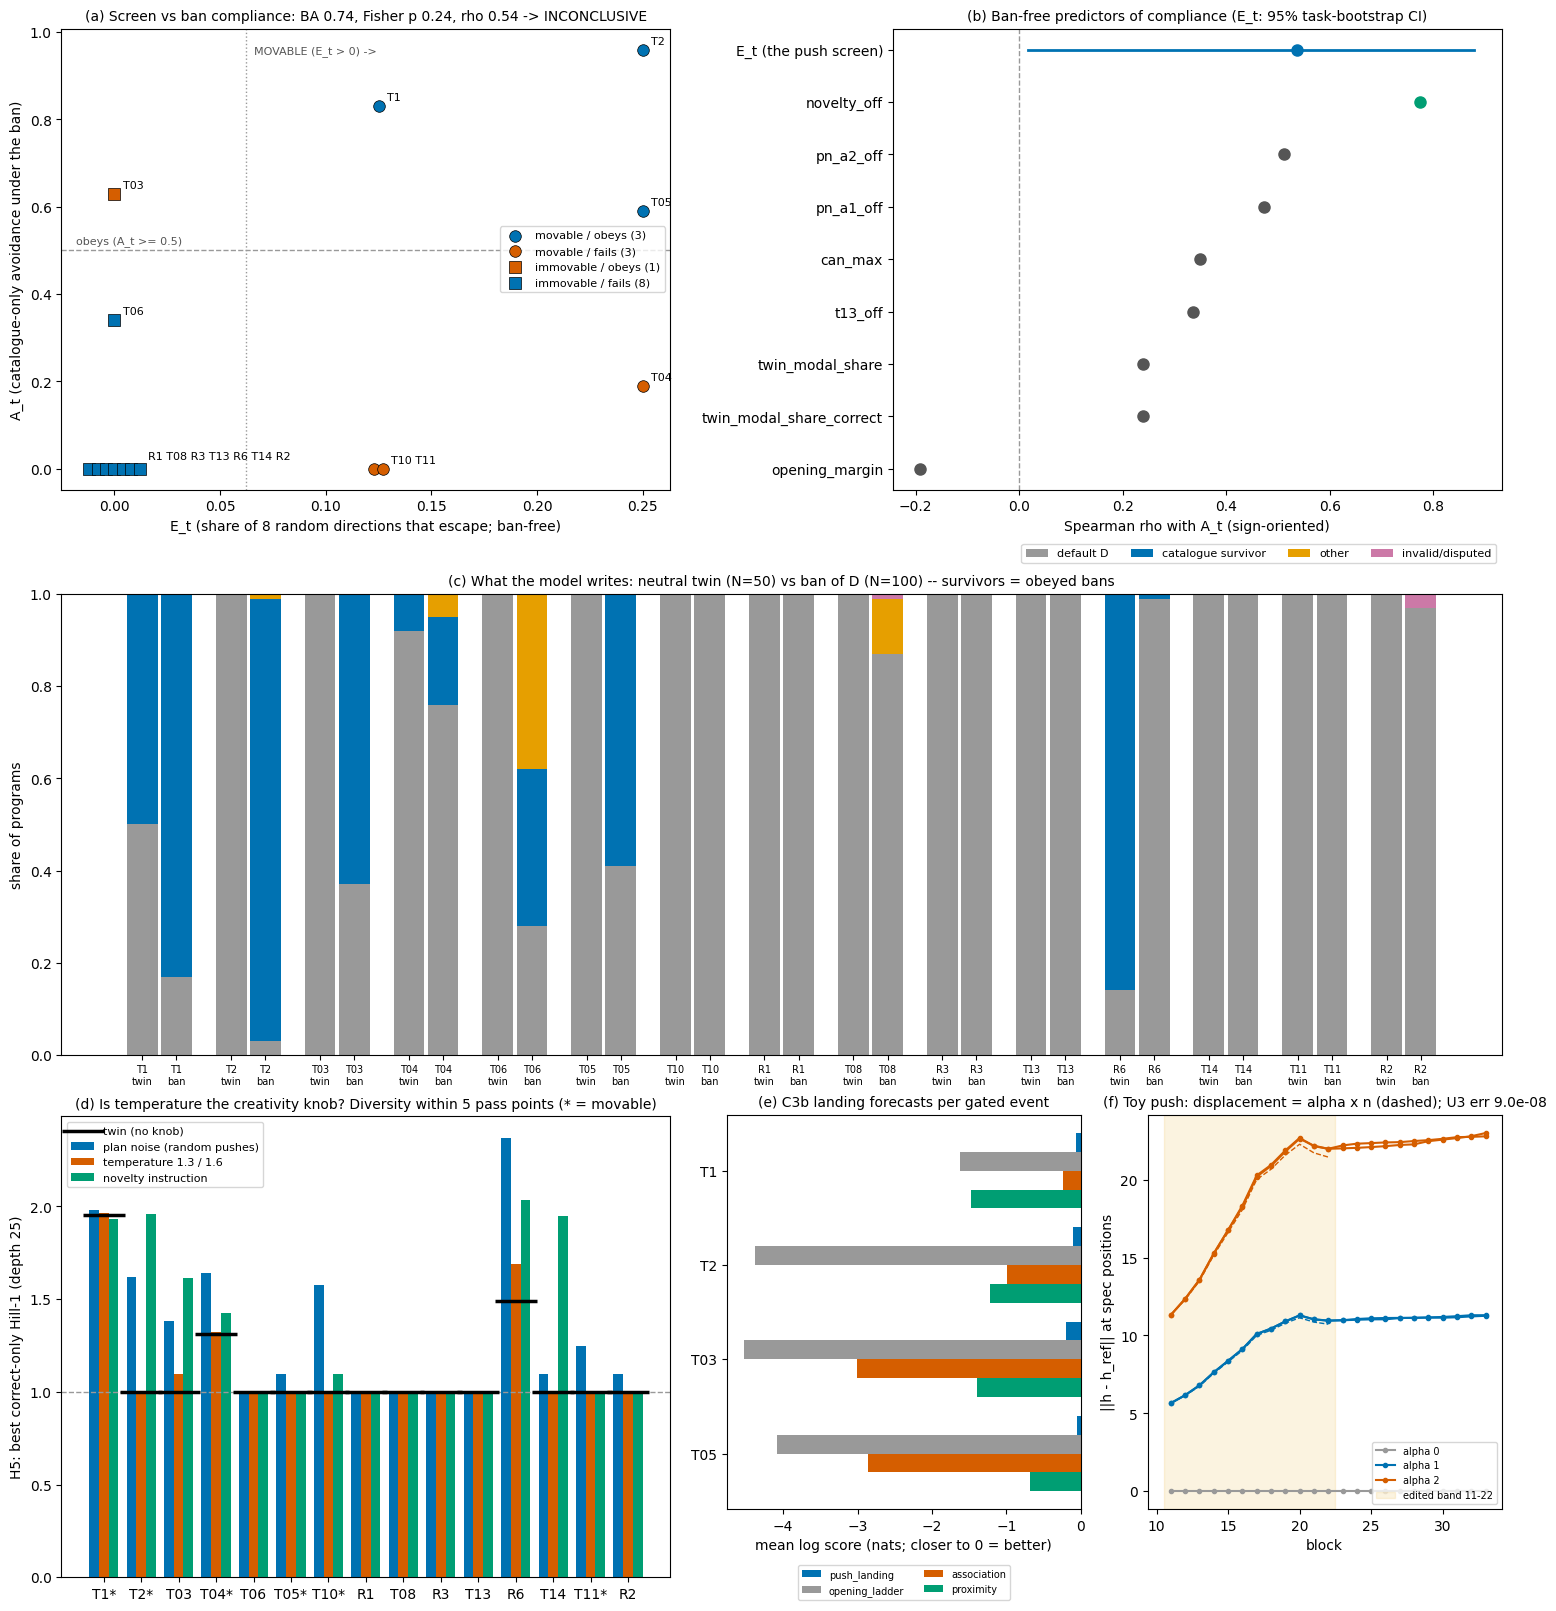

In [26]:
fig = plt.figure(figsize=(15, 16), layout="constrained")
gs = fig.add_gridspec(3, 2)

# (a) fig1: E_t vs A_t, four prediction x outcome groups
ax = fig.add_subplot(gs[0, 0])
style = {(1, 1): ("#0072B2", "o", "movable / obeys"), (1, 0): ("#D55E00", "o", "movable / fails"),
         (0, 1): ("#D55E00", "s", "immovable / obeys"), (0, 0): ("#0072B2", "s", "immovable / fails")}
same_xy = collections.defaultdict(list)  # tasks drawn at the same (E_t, A_t) share one jittered cluster and label
for t in tasks:
    same_xy[(E[t], At[t])].append(t)
jit = {t: 0.004 * (i - (len(ts) - 1) / 2) for ts in same_xy.values() for i, t in enumerate(ts)}
for key, (col, mk, lab) in style.items():
    ts = [t for t in tasks if (int(mv[t]), ot[t]["C_t"]) == key]
    ax.scatter([E[t] + jit[t] for t in ts], [At[t] for t in ts], c=col, marker=mk, s=70, label=f"{lab} ({len(ts)})",
               edgecolor="k", linewidth=0.5, zorder=3)
for (x0, y0), ts in same_xy.items():
    ax.annotate(" ".join(ts), (x0 + max(jit[t] for t in ts), y0), textcoords="offset points",
                xytext=(6, 4 if len(ts) < 3 else 7), fontsize=8)
ax.axhline(COMPLY_THRESH, color="#999999", ls="--", lw=1)
ax.axvline(0.0625, color="#999999", ls=":", lw=1)
ax.text(0.066, 0.97, "MOVABLE (E_t > 0) ->", fontsize=8, color="#555555", va="top")
ax.text(-0.018, COMPLY_THRESH + 0.015, "obeys (A_t >= 0.5)", fontsize=8, color="#555555", ha="left")
ax.set_xlabel("E_t (share of 8 random directions that escape; ban-free)")
ax.set_ylabel("A_t (catalogue-only avoidance under the ban)")
ax.set_title(f"(a) Screen vs ban compliance: BA {ba:.2f}, Fisher p {fp:.2f}, rho {rho:.2f} -> {primary['verdict']}",
             fontsize=10)
ax.legend(fontsize=8, loc="center right")

# (b) fig2: rival forest (sign-oriented Spearman with A_t)
ax = fig.add_subplot(gs[0, 1])
rows_b = [("E_t (the push screen)", rho, primary["bootstrap"]["rho_ci95"])] + sorted(
    [(nm, v["rho_rival_sign_oriented"], None) for nm, v in rv.items()], key=lambda r: -r[1])
for i, (nm, r, ci) in enumerate(rows_b):
    ax.plot([r], [i], "o", color="#0072B2" if i == 0 else ("#009E73" if nm == "novelty_off" else "#555555"), ms=8)
    if ci:
        ax.plot(ci, [i, i], "-", color="#0072B2", lw=2)
ax.axvline(0, color="#999999", ls="--", lw=1)
ax.set_yticks(range(len(rows_b)))
ax.set_yticklabels([r[0] for r in rows_b])
ax.invert_yaxis()
ax.set_xlabel("Spearman rho with A_t (sign-oriented)")
ax.set_title("(b) Ban-free predictors of compliance (E_t: 95% task-bootstrap CI)", fontsize=10)

# (c) fig3: twin vs ban compositions per task
ax = fig.add_subplot(gs[1, :])
cats, vals = [], {"default D": [], "catalogue survivor": [], "other": [], "invalid/disputed": []}
for t in ALL_TASKS:
    D = pre["tasks"][t]["D"]
    for arm, comp, nn in (("twin", c1_arms[t]["twin"]["attempt_comp"], c1_arms[t]["twin"]["n"]),
                          ("ban", ot[t]["composition"], ot[t]["n"])):
        cats.append(f"{t}\n{arm}")
        vals["default D"].append(comp.get(D, 0) / nn)
        vals["other"].append(comp.get("other", 0) / nn)
        vals["invalid/disputed"].append((comp.get("invalid", 0) + comp.get("disputed", 0)) / nn)
        vals["catalogue survivor"].append(1 - vals["default D"][-1] - vals["other"][-1] - vals["invalid/disputed"][-1])
x = np.arange(len(cats)) + np.repeat(np.arange(len(ALL_TASKS)) * 0.6, 2)
bottom = np.zeros(len(cats))
for (k, v), col in zip(vals.items(), ("#999999", "#0072B2", "#E69F00", "#CC79A7")):
    ax.bar(x, v, bottom=bottom, color=col, width=0.9, label=k)
    bottom += np.array(v)
ax.set_xticks(x)
ax.set_xticklabels(cats, fontsize=7)
ax.set_ylabel("share of programs")
ax.set_title("(c) What the model writes: neutral twin (N=50) vs ban of D (N=100) -- survivors = obeyed bans", fontsize=10)
ax.legend(fontsize=8, ncol=4, loc="upper right", bbox_to_anchor=(1, 1.12))

# (d) C1: best correct-only Hill-1 within 5 pass points, per knob
ax = fig.add_subplot(gs[2, 0])
c1_tasks = list(c1["per_task"])
w = 0.26
for j, (kn, col) in enumerate((("PN", "#0072B2"), ("temperature", "#D55E00"), ("novelty", "#009E73"))):
    hs = [(c1["per_task"][t]["hull"].get(kn, {}).get("H5", {}).get("hill") or np.nan) for t in c1_tasks]
    ax.bar(np.arange(len(c1_tasks)) + (j - 1) * w, hs, width=w, color=col,
           label={"PN": "plan noise (random pushes)", "temperature": "temperature 1.3 / 1.6",
                  "novelty": "novelty instruction"}[kn])
ax.scatter(range(len(c1_tasks)), [c1["per_task"][t]["arms"]["twin"]["hill1_rarefied25"] or np.nan for t in c1_tasks],
           marker="_", s=900, linewidths=2.5, color="k", zorder=3, label="twin (no knob)")
ax.axhline(1.0, color="#999999", ls="--", lw=1)
ax.set_xticks(range(len(c1_tasks)))
ax.set_xticklabels([t + ("*" if t in mov else "") for t in c1_tasks])
ax.set_ylabel("H5: best correct-only Hill-1 (depth 25)")
ax.set_title("(d) Is temperature the creativity knob? Diversity within 5 pass points (* = movable)", fontsize=10)
ax.legend(fontsize=8)

# (e) C3b log scores per gated event   +   (f) toy push displacement by block (inset panels side by side)
sub_gs = gs[2, 1].subgridspec(1, 2)
ax = fig.add_subplot(sub_gs[0, 0])
evs = list(c3b_res["per_event"])
for j, (nm, col) in enumerate(zip(FC, ("#0072B2", "#999999", "#D55E00", "#009E73"))):
    ax.barh(np.arange(len(evs)) + (j - 1.5) * 0.2, [c3b_res["per_event"][t][nm]["log_score"] for t in evs],
            height=0.2, color=col, label=nm)
ax.set_yticks(range(len(evs)))
ax.set_yticklabels(evs)
ax.invert_yaxis()
ax.set_xlabel("mean log score (nats; closer to 0 = better)")
ax.set_title("(e) C3b landing forecasts per gated event", fontsize=10)
ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
ax = fig.add_subplot(sub_gs[0, 1])
dS = pre_push["disp_S"]
for i in range(B):
    if alphas[i] == 0 and i > 0:
        continue
    ax.plot(CAPTURE_BLOCKS, dS[i], "-o", ms=3, color={0.0: "#999999", 1.0: "#0072B2", 2.0: "#D55E00"}[alphas[i]],
            label=f"alpha {alphas[i]:g}" if alphas.index(alphas[i]) == i else None)
for al, col in ((1.0, "#0072B2"), (2.0, "#D55E00")):
    ax.plot(BAND, [al * float(n[l].mean()) for l in BAND], "--", color=col, lw=1)
ax.axvspan(BAND[0] - 0.5, BAND[-1] + 0.5, color="#E69F00", alpha=0.12, label="edited band 11-22")
ax.set_xlabel("block")
ax.set_ylabel("||h - h_ref|| at spec positions")
ax.set_title(f"(f) Toy push: displacement = alpha x n (dashed); U3 err {u3:.1e}", fontsize=10)
ax.legend(fontsize=7)
plt.show()

**Reading the results.**

* **Prediction vs outcome (a, summary table).** The screen predicts the direction of compliance (rho 0.54), but its
  binary call misses 4 of 15 tasks. T03 obeys though immovable. T04, T10 and T11 are movable but ignore the ban.
  Under the pre-registered rule, C3a is INCONCLUSIVE.
* **Rivals (b).** Simply asking for a novel algorithm (`novelty_off`) tracks compliance better than the activation
  screen. The prompting ceiling stays the baseline to beat.
* **Compositions (c).** The ban often flips the model to *one* survivor (T1: DFS -> BFS; T03: full sort -> size-k
  heap), and leaves others untouched (T10, T11: 100% default). On R6 it backfires: the ban "Do not use a hand-written
  binary search" makes the model write binary search 99% of the time.
* **C1 (d): is temperature the creativity knob? Not here.**
  * Within 5 pass points, temperature 1.3 / 1.6 lifts algorithm diversity above the twin's on only 2 of 15 tasks
    (T03, R6). T2 stays at Hill-1 1.00.
  * Fresh random pushes on the task representation (plan noise) lift it on 9 (T2: 1.00 -> 1.62; T10: 1.00 -> 1.58;
    R6: 1.5 -> 2.37).
  * The novelty instruction lifts 6, sometimes the most (T2: 1.96), but costs a lot of correctness elsewhere (pass
    0.08 on T06, 0.36 on T1).

  The counts are printed above the figure.
* **Toy push (f).** The edited displacement equals alpha x n at every band block (dashed). It is zero before the band
  and for alpha-0 rows, and it evolves freely after the band. This is what GPU test U3 checks on the real model.

**To reproduce everything from scratch**, clone the repository and see `reproducibility.md`:
`uv pip install -r pyproject.toml`, then `python method.py`. That takes about 2 GPU-hours on a 16 GB card;
`python method.py --from analysis` re-analyses the stored samples on CPU.